# AKI–KDIGO Severity-Regime Modeling on MIMIC-IV
### Faithful port of the PEMDT v3.3 multi-state engine, adapted to KDIGO

This notebook ports the **real** PEMDT engine
(`PEMDT_v2_stepbystep_v3.3_FULLRUN`) to acute kidney injury, modeling KDIGO
severity as a latent ordered regime (`No_AKI → KDIGO_1 → KDIGO_2 → KDIGO_3`)
for early, calibrated, glass-box warning of escalation.

**This build = Layer 1 (faithful).** The v3.3 system has three layers; this
notebook ships Layer 1 verbatim-in-spirit and scaffolds Layers 2–3 as the next
builds:

| Layer | v3.3 source | Status here |
|---|---|---|
| **L1 — Multi-state severity HMM** | cells 8/38/40/42: `_logpdf_gauss`, `default_state_means/scales/transition`, JAX `forward_filter`, `run_filter_patient` | ✅ **ported** (this build), adapted to 4 KDIGO states |
| **L2 — Hierarchical Bayesian emissions** | cells 51–58: NumPyro `hierarchical_emission_model`, 5-fold patient CV | ✅ built but **OFF by default** — collapses below chance on max-arm KDIGO labels (see §9); Layer 1 is the model of record |
| **L3 — Causal layer** | cells 64–80: propensity, `make_treatment_transitions`, `forward_filter_treatment`, doubly-robust **AIPW ATE** | ⏳ optional next build (faithful to v3.3; the dropped "where-to-fuse" ablation was *not* part of v3.3) |

**What was actually reused.** The JAX `forward_filter` is copied verbatim; the
emission geometry (`mean = STATE_PROGRESSION × FEATURE_DIRECTION`, z-scored,
`FEATURE_WEIGHTS`-weighted, age-bracketed tridiagonal transitions) follows v3.3
exactly. Only adaptations: 4 KDIGO states instead of 5 generic severity states,
and AKI features (`creatinine_ratio`, `dSCr_48h`, `uo_rate`, `bun`) instead of
ICU vitals.

---

### 🔧 v2 fixes (after the first full-MIMIC run exposed bad labels)
- **Urine output**: subtract GU irrigant-in (227488), score only charted hours, clip to ≤20 mL/kg/h, validate weight (20–300 kg) — the old run had `uo_rate` up to 575,000 and irrigant counted as urine.
- **`dSCr_48h`** now computed from real creatinine draws (was ~0 everywhere via an LOCF rolling-min artifact).
- **RRT** is now streamed from `procedureevents` and is an absorbing Stage-3 state (was never wired — `rrt_on` was 0% across 6.6 M rows).
- **Emissions** are now clinically anchored to KDIGO bands instead of population z-scores (z-scoring flattened the signal because the cohort is full of AKI). `EMISSION_MODE='zscore'` restores the original v3.3 geometry for comparison.
- Output renamed **`aki_cohort_v2.parquet`** so the stale buggy cohort is never silently reloaded — **re-run the ETL cell**.
- New **cross-check cell** (Cohen's κ vs an independent KDIGO derivation).

### ⚠️ Honest status
1. **Runs on synthetic data** until MIMIC is wired in. Default `MIMIC_ROOT`
   auto-detects `/Users/sumiyasayeed/Documents/mimic4`. Cell 5 synthesizes a
   cohort with the same schema as `aki_cohort.parquet` when the parquet is absent.
2. **Layer-1 discrimination is intentionally modest (AUROC ≈ 0.68).** This
   *matches* v3.3's own note that "Layer 1 AUC is capped ~0.68" — Layer 2
   (personalised emissions) is what lifts it. Don't read the synthetic numbers
   as the final result.
3. **KDIGO labels not yet cross-checked vs `mimic-code`** (`kdigo_creatinine` /
   `kdigo_uo` / `kdigo_stages`). Flagged TODO in cell 3 (Milestone M1).
4. **Synthetic results are plumbing, not evidence.** The signal is injected by
   construction; the scientific claim needs MIMIC + grouped LOPO.

### Switch synthetic → real MIMIC
```python
build_cohort(limit=50)   # cell 4 — writes derived/aki_cohort.parquet
# restart & run all: cell 5 auto-loads the parquet instead of synthesizing.
```


## 1 · Config
v3.3-faithful knobs (cells 6 & 38) adapted to KDIGO: states, `STATE_PROGRESSION`, `FEATURE_DIRECTION`/`WEIGHTS`, age brackets, `VALID_RANGES`, KDIGO thresholds.


In [1]:
# ============================================================================
# 1 · CONFIG  —  MIMIC item IDs + v3.3-faithful engine knobs (KDIGO) + fixes
# ============================================================================
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")

from dataclasses import dataclass
from pathlib import Path
import numpy as np
import pandas as pd

# --- Paths (MIMIC auto-detect) ----------------------------------------------
MIMIC_CANDIDATES = [Path("/Users/sumiyasayeed/Documents/mimic4/mimiciv"),
                    Path("/Users/sumiyasayeed/Documents/mimic4")]
MIMIC_ROOT = next((p for p in MIMIC_CANDIDATES if p.exists()), MIMIC_CANDIDATES[-1])
HOSP_DIR, ICU_DIR = MIMIC_ROOT / "hosp", MIMIC_ROOT / "icu"
PROJECT_ROOT = Path.cwd()
DERIVED_DIR = PROJECT_ROOT / "derived"; DERIVED_DIR.mkdir(exist_ok=True)
# v2 = after the label/ETL fixes. The old aki_cohort.parquet (buggy labels) is
# left untouched and is NOT loaded, so stale results can't sneak back in.
COHORT_PARQUET = DERIVED_DIR / "aki_cohort_v2.parquet"

# --- MIMIC-IV item IDs ------------------------------------------------------
CREATININE_ITEMIDS = [50912, 52546]                 # hosp/labevents, mg/dL
BUN_ITEMIDS        = [51006]
# Urine output — canonical MIT-LCP pivoted-UO set. GU Irrigant *In* (227488) is
# fluid going IN and must be SUBTRACTED, not counted as output (FIX).
URINE_POSITIVE_ITEMIDS = [226559, 226560, 226561, 226584, 226563, 226564,
                          226565, 226567, 226557, 226558, 227489]
URINE_NEGATIVE_ITEMIDS = [227488]                   # GU Irrigant Volume In -> subtract
UO_ITEMIDS = URINE_POSITIVE_ITEMIDS + URINE_NEGATIVE_ITEMIDS
WEIGHT_ITEMIDS = [226512, 224639]                   # Admit Wt, Daily Wt (kg)
MAP_ITEMIDS    = [220052, 220181, 225312]
VASO_ITEMIDS   = [221906, 221749, 221662, 222315, 221289]
NEPHROTOX_IV_ITEMIDS = [225798, 225875, 225902, 221794]   # vanco/genta/tobra/furosemide
RRT_PROCEDURE_ITEMIDS = [225441, 225802, 225803, 225805, 225809, 225955]  # HD/CRRT/CVVHD/PD/CVVHDF/SCUF

# Physiologic validity filter — drop implausible raw values before staging/emission.
WEIGHT_VALID = (20.0, 300.0)        # kg
UO_RATE_CLIP = (0.0, 20.0)          # mL/kg/h (anything above is a charting artifact)
# Urine output is the strongest predictor but charted only ~52% of hours. A
# causal (trailing) rolling mean of this many hours lifts emission coverage to
# ~86% and denoises it (validated: +~0.05 AUROC, +~0.04 AUPRC). Set 0 to disable.
UO_EMIT_SMOOTH_H = 6

# --- Multi-state HMM: the 4 ordered KDIGO regimes ---------------------------
STATE_LABELS = ["No_AKI", "KDIGO_1", "KDIGO_2", "KDIGO_3"]
N_STATES = len(STATE_LABELS)
STATE_PROGRESSION = np.array([0.0, 1.0, 2.0, 3.0])   # z-units (used only if EMISSION_MODE='zscore')
ABSORBING_RRT_STATE = 3

FEATURES = ["creatinine_ratio", "dSCr_48h", "uo_rate", "bun"]
FEATURE_DIRECTION = {"creatinine_ratio": +1, "dSCr_48h": +1, "uo_rate": -1, "bun": +1}
FEATURE_WEIGHTS   = {"creatinine_ratio": 1.6, "dSCr_48h": 1.3, "uo_rate": 1.5, "bun": 1.0}
VALID_RANGES = {"creatinine_ratio": (0.2, 15), "dSCr_48h": (-2, 15),
                "uo_rate": (0.0, 20), "bun": (1, 250)}

# --- Emission model ----------------------------------------------------------
# 'clinical' (default, FIX): per-state Gaussian means anchored to KDIGO clinical
#   thresholds, in RAW units — strong, interpretable signal.
# 'zscore'  : the original v3.3 geometry (z-score vs population × STATE_PROGRESSION
#   × FEATURE_DIRECTION). Kept for faithful comparison; flattened the signal on
#   real AKI data because the population already contains heavy AKI tails.
EMISSION_MODE = "clinical"
# (means, sds) per state for each feature. creatinine_ratio means track KDIGO
# ratio bands (1.5-1.9 / 2.0-2.9 / >=3); uo_rate tracks the <0.5 / <0.3 cut-offs.
CLINICAL_ANCHORS = {
    "creatinine_ratio": ([1.00, 1.60, 2.40, 3.50], [0.30, 0.35, 0.50, 0.90]),
    "dSCr_48h":         ([0.00, 0.35, 0.60, 1.00], [0.15, 0.20, 0.30, 0.50]),
    "uo_rate":          ([1.00, 0.45, 0.30, 0.10], [0.40, 0.18, 0.13, 0.08]),
    "bun":              ([15.0, 30.0, 45.0, 70.0], [9.0, 12.0, 16.0, 22.0]),
}
# Population z-score fallback (only used in 'zscore' mode); filled from TRAIN.
GLOBAL_STATS = {"creatinine_ratio": (1.0, 0.5), "dSCr_48h": (0.1, 0.4),
                "uo_rate": (0.9, 0.5), "bun": (25.0, 18.0)}

AGE_BRACKETS = [(0, 45), (45, 65), (65, 80), (80, 200)]
PRIOR_BELIEF = np.array([0.85, 0.10, 0.04, 0.01])

# --- KDIGO 2012 thresholds ---------------------------------------------------
@dataclass(frozen=True)
class KDIGOThresholds:
    abs_rise_48h: float = 0.3; ratio_stage1: float = 1.5
    ratio_stage2: float = 2.0; ratio_stage3: float = 3.0; scr_stage3_abs: float = 4.0
    uo_low_rate: float = 0.5; uo_s1_hours: int = 6; uo_s2_hours: int = 12
    uo_s3_rate: float = 0.3; uo_s3_hours: int = 24; anuria_hours: int = 12
KDIGO = KDIGOThresholds()

@dataclass
class CohortConfig:
    min_age: int = 18; min_los_days: float = 1.5; min_creatinine_measurements: int = 2
    default_egfr: float = 75.0; grid_freq: str = "1h"; nephrotox_halflife_h: float = 24.0
COHORT = CohortConfig()

@dataclass
class EvalConfig:
    horizons_h: tuple = (12, 24, 48)
    # 200 resamples give stable 95% CIs at this scale (~3 min); raise BOOTSTRAP_N
    # for tighter intervals, lower it to go faster.
    n_bootstrap: int = int(os.environ.get("BOOTSTRAP_N", "200"))
    bootstrap_alpha: float = 0.05; random_state: int = 7
EVAL = EvalConfig()

# --- Layer 2 (hierarchical personalized emissions) ---------------------------
# Knobs are env-overridable so a full "Run All" isn't punishing:
#   L2_RUN=0 skips it; L2_STEPS / L2_MAX_PATIENTS tune SVI cost.
@dataclass
class Layer2Config:
    run: bool = os.environ.get("L2_RUN", "0") == "1"   # OFF by default — see Layer-2 note
    max_patients: int = int(os.environ.get("L2_MAX_PATIENTS", "1500"))  # SVI subsample cap
    n_folds: int = 5              # patient-level CV
    svi_steps_max: int = int(os.environ.get("L2_STEPS", "1500"))
    svi_lr: float = 1e-2
    svi_patience: int = 200       # early stop
    svi_tol: float = 1.0          # ELBO units
L2 = Layer2Config()
COHORT_SUMMARY_PARQUET = DERIVED_DIR / "aki_cohort_summary.parquet"
GOLD_SAMPLE_STAYS = 800   # stays sampled for the M1 mimic-code gold-standard check

# --- Layer 3 (causal: nephrotoxin -> AKI escalation, doubly-robust AIPW) ------
@dataclass
class Layer3Config:
    run: bool = os.environ.get("L3_RUN", "1") == "1"
    t_window_h: int = 24          # treatment defined in [0, t_window); outcome after
    cf_beta: float = 0.5          # assumed nephrotoxin->transition effect (counterfactual belief)
    cf_max_patients: int = 1500   # cap for the counterfactual-belief loop
    n_bootstrap: int = 300
L3 = Layer3Config()

# Canonical MIMIC timestamp format (kills the slow dateutil per-element warning).
MIMIC_TS_FMT = "%Y-%m-%d %H:%M:%S"
def to_dt(s):
    return pd.to_datetime(s, format=MIMIC_TS_FMT, errors="coerce")

print("Config loaded (v3.3-faithful + label/ETL fixes).")
print("  States       :", STATE_LABELS, "| emission mode:", EMISSION_MODE)
print("  Output        :", COHORT_PARQUET.name, "(v2 — stale v1 parquet is not loaded)")
print("  MIMIC_ROOT   :", MIMIC_ROOT, "(exists:", MIMIC_ROOT.exists(), ")")


Config loaded (v3.3-faithful + label/ETL fixes).
  States       : ['No_AKI', 'KDIGO_1', 'KDIGO_2', 'KDIGO_3'] | emission mode: clinical
  Output        : aki_cohort_v2.parquet (v2 — stale v1 parquet is not loaded)
  MIMIC_ROOT   : /Users/sumiyasayeed/Documents/mimic4/mimiciv (exists: True )


## 2 · Layer 1 — Multi-state severity HMM (faithful port)
The JAX `forward_filter` (jit + `lax.scan`) is copied verbatim from v3.3 cell 40. Emissions are z-scored with per-state means = `STATE_PROGRESSION × FEATURE_DIRECTION`, weighted by `FEATURE_WEIGHTS`; transitions are tridiagonal with age-bracketed recovery.


In [2]:
# ============================================================================
# 2 · LAYER 1 — Multi-state severity HMM  (faithful port of PEMDT v3.3)
# ============================================================================
# Ported from PEMDT_v2_stepbystep_v3.3 cells 8/38/40/42:
#   * _logpdf_gauss, age_bracket
#   * default_state_means / default_state_scales / default_transition
#   * the JAX `forward_filter` (jit + lax.scan) — copied VERBATIM
#   * run_filter_patient wrapper (per-patient z-scoring + mask + weights)
# The only adaptation is N_STATES = 4 (KDIGO) instead of 5 (generic severity).
import jax
import jax.numpy as jnp
import numpy as np
from scipy.stats import norm   # used by the LLR attribution below

# ---- helpers (v3.3 cell 8) -------------------------------------------------
def _logpdf_gauss(x, mu, sigma):
    return -0.5 * jnp.log(2 * jnp.pi) - jnp.log(sigma) - 0.5 * ((x - mu) / sigma) ** 2

def age_bracket(age):
    for k, (lo, hi) in enumerate(AGE_BRACKETS):
        if lo <= age < hi:
            return k
    return len(AGE_BRACKETS) - 1

# ---- population emission geometry (v3.3 cell 38) ---------------------------
def default_state_means():
    """means[k, f] = STATE_PROGRESSION[k] * FEATURE_DIRECTION[f]  (in z-units)."""
    means = np.zeros((N_STATES, len(FEATURES)))
    for fi, f in enumerate(FEATURES):
        for ki, delta in enumerate(STATE_PROGRESSION):
            means[ki, fi] = delta * FEATURE_DIRECTION[f]
    return means

def default_state_scales():
    """Wider emission scale for the more-severe regimes (more heterogeneity)."""
    scales = np.ones((N_STATES, len(FEATURES)))
    scales[2, :] = 1.3   # KDIGO_2 (analogue of v3.3 'Severe')
    scales[3, :] = 1.5   # KDIGO_3 (analogue of v3.3 'Critical')
    return scales

def default_transition(age_idx=1):
    """Tridiagonal: +1 escalation (fixed), -1 recovery (age-bracketed). v3.3 cell 38."""
    recovery_by_age = [0.20, 0.15, 0.10, 0.08]
    escalation = 0.05
    rec = recovery_by_age[age_idx]
    A = np.zeros((N_STATES, N_STATES))
    for k in range(N_STATES):
        if k > 0:            A[k, k - 1] = rec
        if k < N_STATES - 1: A[k, k + 1] = escalation
        A[k, k] = 1.0 - A[k].sum()
    return A

STATE_MEANS_POP = default_state_means()
STATE_SCALES_POP = default_state_scales()

# ---- clinically-anchored emissions (FIX, default) --------------------------
# Per-state Gaussian means/scales in RAW clinical units, anchored to the KDIGO
# bands (see CLINICAL_ANCHORS). This replaces population z-scoring, which
# flattened the signal because the cohort itself is full of AKI.
def clinical_state_means():
    M = np.zeros((N_STATES, len(FEATURES)))
    for fi, f in enumerate(FEATURES): M[:, fi] = CLINICAL_ANCHORS[f][0]
    return M
def clinical_state_scales():
    S = np.ones((N_STATES, len(FEATURES)))
    for fi, f in enumerate(FEATURES): S[:, fi] = CLINICAL_ANCHORS[f][1]
    return S
CLINICAL_MEANS = clinical_state_means()
CLINICAL_SCALES = clinical_state_scales()

def active_means_scales():
    """Return (means, scales) for the configured EMISSION_MODE."""
    return (CLINICAL_MEANS, CLINICAL_SCALES) if EMISSION_MODE == "clinical" \
        else (STATE_MEANS_POP, STATE_SCALES_POP)

# ---- the JAX forward filter (v3.3 cell 40 — VERBATIM) ----------------------
@jax.jit
def forward_filter(z_obs, mask, state_means, state_scales, transition, prior, weights):
    """Canonical HMM forward filter.
    z_obs/mask: (T,F); state_means/scales: (K,F); transition: (K,K); prior: (K,);
    weights: (F,). Returns beliefs (T,K). Off-by-one corrected; outputs clipped."""
    z_clean = jnp.where(mask > 0, z_obs, 0.0)
    # t=0: emission applied directly to prior (no prediction step)
    log_em0 = (mask[0][None, :] * weights[None, :] *
               _logpdf_gauss(z_clean[0][None, :], state_means, state_scales)).sum(axis=1)
    log_post0 = jnp.log(prior + 1e-30) + log_em0
    log_post0 = log_post0 - jnp.max(log_post0)
    post0 = jnp.exp(log_post0); post0 = post0 / (post0.sum() + 1e-30)

    def step(belief, inputs):
        z, m = inputs
        log_pred = jnp.log(belief @ transition + 1e-30)
        log_em = (m[None, :] * weights[None, :] *
                  _logpdf_gauss(z[None, :], state_means, state_scales)).sum(axis=1)
        log_post = log_pred + log_em
        log_post = log_post - jnp.max(log_post)
        post = jnp.exp(log_post); post = post / (post.sum() + 1e-30)
        return post, post

    _, tail = jax.lax.scan(step, post0, (z_clean[1:], mask[1:]))
    beliefs = jnp.concatenate([post0[None, :], tail], axis=0)
    return jnp.clip(beliefs, 0.0, 1.0)

# ---- population z-score parameters from TRAIN (v3.3 "Step 1.3") -------------
def compute_global_stats(train_df, features=FEATURES):
    """Population (mu, sd) per feature, used to z-score emissions. Robust to NaN."""
    stats = {}
    for f in features:
        v = pd.to_numeric(train_df[f], errors="coerce").dropna()
        lo, hi = VALID_RANGES.get(f, (-np.inf, np.inf))
        v = v[(v > lo) & (v < hi)]
        mu = float(v.mean()) if len(v) else GLOBAL_STATS[f][0]
        sd = float(v.std(ddof=0)) if len(v) > 1 and v.std(ddof=0) > 1e-6 else GLOBAL_STATS[f][1]
        stats[f] = (mu, sd)
    return stats

# personal_stats hook (Layer-2 fills this; falls back to global for Layer 1)
personal_stats: dict = {}

# ---- per-patient wrapper (v3.3 cell 42) ------------------------------------
def run_filter_patient(group, state_means=None, state_scales=None, global_stats=None,
                       weights=None, use_personal=True, prior=PRIOR_BELIEF,
                       emission_mode=None, rrt_absorb=True):
    """Forward-filter one stay.

    emission_mode='clinical' -> feed RAW feature values against CLINICAL_MEANS
      (no z-scoring; global_stats unused).
    emission_mode='zscore'   -> per-patient/global z-scores against STATE_MEANS_POP.
    rrt_absorb=True          -> once rrt_on fires, belief is pinned to Stage 3
                                (RRT is an absorbing severe state)."""
    mode = emission_mode or EMISSION_MODE
    if state_means is None or state_scales is None:
        state_means, state_scales = active_means_scales()
    pid = group["stay_id"].iloc[0]
    pat_stats = (personal_stats.get(pid, global_stats) if (use_personal and global_stats) else global_stats)
    age = float(group["anchor_age"].iloc[0]) if "anchor_age" in group.columns and \
        pd.notna(group["anchor_age"].iloc[0]) else 65.0
    trans = default_transition(age_bracket(age))

    obs = np.zeros((len(group), len(FEATURES)))
    msk = np.zeros_like(obs)
    for j, f in enumerate(FEATURES):
        raw = pd.to_numeric(group[f], errors="coerce").values
        lo, hi = VALID_RANGES.get(f, (-np.inf, np.inf))
        ok = ~np.isnan(raw) & (raw > lo) & (raw < hi)
        if mode == "clinical":
            obs[ok, j] = raw[ok]
        else:
            mu, sd = (pat_stats or GLOBAL_STATS)[f]
            obs[ok, j] = (raw[ok] - mu) / sd
        msk[ok, j] = 1.0

    if weights is None:
        weights = np.array([FEATURE_WEIGHTS[f] for f in FEATURES])
    beliefs = np.asarray(forward_filter(
        jnp.array(obs), jnp.array(msk), jnp.array(state_means), jnp.array(state_scales),
        jnp.array(trans), jnp.array(prior), jnp.array(weights)))
    beliefs = np.clip(beliefs, 0.0, 1.0)

    # RRT -> absorbing Stage 3 (creatinine no longer reflects renal function).
    if rrt_absorb and "rrt_on" in group.columns:
        on = pd.to_numeric(group["rrt_on"], errors="coerce").fillna(0).values > 0
        if on.any():
            onehot = np.zeros(N_STATES); onehot[ABSORBING_RRT_STATE] = 1.0
            beliefs[on] = onehot

    out = group.copy().reset_index(drop=True)
    for k, lbl in enumerate(STATE_LABELS):
        out[f"p_{lbl}"] = beliefs[:, k]
    out["p_AKI"] = 1.0 - beliefs[:, 0]
    out["risk_score"] = np.clip(beliefs[:, 2] + beliefs[:, 3], 0.0, 1.0)  # p(KDIGO>=2)
    return out

# ---- glass-box LLR attribution (z-score form, matches v3.3 emission) -------
FEATURE_LABELS = {"creatinine_ratio": "rising creatinine", "dSCr_48h": "48h creatinine jump",
                  "uo_rate": "falling urine output", "bun": "rising BUN"}

def attribute_window(row, global_stats=None, from_state=0, to_state=1, top_k=2,
                     emission_mode=None):
    """LLR per feature between adjacent regimes, in the engine's own space."""
    mode = emission_mode or EMISSION_MODE
    m, s = active_means_scales()
    best = []
    for f in FEATURES:
        x = pd.to_numeric(pd.Series([row.get(f)]), errors="coerce").iloc[0]
        if np.isnan(x):
            continue
        fi = FEATURES.index(f)
        if mode == "clinical":
            val = x
        else:
            mu, sd = (global_stats or GLOBAL_STATS)[f]; val = (x - mu) / sd
        llr = (norm.logpdf(val, m[to_state, fi], s[to_state, fi])
               - norm.logpdf(val, m[from_state, fi], s[from_state, fi])) * FEATURE_WEIGHTS[f]
        best.append((f, float(llr)))
    best.sort(key=lambda kv: kv[1], reverse=True)
    drivers = [FEATURE_LABELS[f] for f, v in best[:top_k] if v > 0]
    sev = STATE_LABELS[to_state]
    return (f"{sev} risk rising: " + " + ".join(drivers)) if drivers else f"{sev} risk stable"

print("Layer-1 engine ported (JAX forward_filter, default_state_means/scales/transition,")
print("run_filter_patient, compute_global_stats, attribute_window).  Devices:", jax.devices())


Layer-1 engine ported (JAX forward_filter, default_state_means/scales/transition,
run_filter_patient, compute_global_stats, attribute_window).  Devices: [CpuDevice(id=0)]


## 3 · KDIGO 2012 staging (Phase 0 labels)
`Stage(t) = max(creatinine-arm, urine-output-arm, RRT-arm)`.

**TODO (M1):** cross-check vs MIT-LCP `mimic-code` (`kdigo_creatinine`, `kdigo_uo`, `kdigo_stages`).


In [3]:
# ============================================================================
# 3 · KDIGO 2012 STAGING  —  ground-truth labels on the hourly grid
# ============================================================================
# Stage(t) = max(creatinine-stage, urine-output-stage, RRT-stage).
# These produce the *labels* we validate against — the latent regime the engine
# infers is a separate, earlier-moving quantity.

def creatinine_stage(ratio, dscr_48h, scr):
    """KDIGO creatinine arm. ratio=SCr/baseline, dscr_48h=max rise over 48 h."""
    ratio = -np.inf if ratio is None or (isinstance(ratio, float) and np.isnan(ratio)) else ratio
    dscr_48h = -np.inf if dscr_48h is None or (isinstance(dscr_48h, float) and np.isnan(dscr_48h)) else dscr_48h
    scr = -np.inf if scr is None or (isinstance(scr, float) and np.isnan(scr)) else scr
    if ratio >= KDIGO.ratio_stage3 or scr >= KDIGO.scr_stage3_abs:
        return 3
    if ratio >= KDIGO.ratio_stage2:
        return 2
    if ratio >= KDIGO.ratio_stage1 or dscr_48h >= KDIGO.abs_rise_48h:
        return 1
    return 0


def urine_output_stage(uo_6h, uo_12h, uo_24h):
    """KDIGO urine-output arm from rolling mean rates (mL/kg/h) over windows.

    Hourly-grid approximation of the 'sustained for >= N h' criteria: a window
    mean below threshold means the rate stayed low across that window. Anuria is
    treated as ~0 mL/kg/h sustained >= 12 h (captured by the 12 h window ~ 0)."""
    def low(x, thr):
        return (x is not None) and (not (isinstance(x, float) and np.isnan(x))) and (x < thr)
    # Stage 3: < 0.3 for >= 24 h, OR anuria (~0) for >= 12 h.
    if low(uo_24h, KDIGO.uo_s3_rate) or (uo_12h is not None and not np.isnan(uo_12h) and uo_12h < 0.05):
        return 3
    if low(uo_12h, KDIGO.uo_low_rate):     # < 0.5 for >= 12 h
        return 2
    if low(uo_6h, KDIGO.uo_low_rate):      # < 0.5 for 6-12 h
        return 1
    return 0


def kdigo_stage_row(row):
    """max() of the three arms for one harmonized hour-row."""
    c = creatinine_stage(row.get("creatinine_ratio"), row.get("dSCr_48h"), row.get("creatinine"))
    u = urine_output_stage(row.get("uo_6h"), row.get("uo_12h"), row.get("uo_24h"))
    r = 3 if row.get("rrt_on", 0) else 0
    return int(max(c, u, r))


def add_kdigo_stage(df):
    """Vectorized-ish stage derivation for a harmonized per-stay-hour frame."""
    df = df.copy()
    df["kdigo_cr"]  = [creatinine_stage(a, b, c) for a, b, c in
                       zip(df.get("creatinine_ratio"), df.get("dSCr_48h"), df.get("creatinine"))]
    df["kdigo_uo"]  = [urine_output_stage(a, b, c) for a, b, c in
                       zip(df.get("uo_6h"), df.get("uo_12h"), df.get("uo_24h"))]
    df["kdigo_rrt"] = np.where(df.get("rrt_on", 0) > 0, 3, 0)
    df["kdigo_stage"] = df[["kdigo_cr", "kdigo_uo", "kdigo_rrt"]].max(axis=1).astype(int)
    return df


def rolling_uo_rates(stay_df, uo_rate_col="uo_rate"):
    """Add uo_6h/uo_12h/uo_24h rolling-mean rates (mL/kg/h) on an hourly grid.

    Assumes stay_df is one stay, sorted by `hour`, with `uo_rate` already in
    mL/kg/h per hour (0 where charted-and-empty, NaN where charting absent)."""
    s = stay_df.sort_values("hour").copy()
    r = s[uo_rate_col]
    s["uo_6h"]  = r.rolling(KDIGO.uo_s1_hours, min_periods=KDIGO.uo_s1_hours).mean()
    s["uo_12h"] = r.rolling(KDIGO.uo_s2_hours, min_periods=KDIGO.uo_s2_hours).mean()
    s["uo_24h"] = r.rolling(KDIGO.uo_s3_hours, min_periods=KDIGO.uo_s3_hours).mean()
    return s

print("KDIGO staging loaded: creatinine_stage, urine_output_stage, add_kdigo_stage, rolling_uo_rates.")


KDIGO staging loaded: creatinine_stage, urine_output_stage, add_kdigo_stage, rolling_uo_rates.


## 4 · Phase 0 ETL → `aki_cohort.parquet`
Streams MIMIC filtered to the item IDs, applies cohort + exclusions, baseline creatinine, weight, hourly harmonization. Runs only when `MIMIC_ROOT` is mounted — call `build_cohort(limit=50)`.


In [4]:
# ============================================================================
# 4 · PHASE 0 ETL  —  cohort, baseline, hourly harmonization -> aki_cohort.parquet
# ============================================================================
# The "unglamorous 40%". chartevents (~40 GB) and labevents (~18 GB) cannot be
# loaded whole, so we pre-filter to the item IDs above with DuckDB streaming
# (falls back to chunked pandas). Each helper degrades gracefully and tells you
# exactly which file is missing rather than dying obscurely.
import glob as _glob

try:
    import duckdb
    _HAS_DUCKDB = True
except Exception:
    _HAS_DUCKDB = False


if not _HAS_DUCKDB:
    print("NOTE: duckdb not importable in this kernel -> using slower chunked-pandas "
          "streaming. `pip install duckdb` in THIS kernel for a big speedup.")

def _ensure_dt(df, col="charttime"):
    """Return a copy of df with `col` guaranteed datetime64 (merge_asof needs
    both sides the same dtype). No-op if already datetime."""
    if df is None or col not in getattr(df, "columns", []):
        return df
    if not pd.api.types.is_datetime64_any_dtype(df[col]):
        df = df.copy(); df[col] = to_dt(df[col])
    return df


def _resolve(path_noext):
    """Return the existing .csv or .csv.gz path for a MIMIC table stem, or None."""
    for ext in (".csv", ".csv.gz"):
        p = Path(str(path_noext) + ext)
        if p.exists():
            return p
    hits = _glob.glob(str(path_noext) + "*")
    return Path(hits[0]) if hits else None


def _file_columns(path):
    """Column names of a (possibly gzipped) CSV without reading the body."""
    if _HAS_DUCKDB:
        return list(duckdb.query(f"SELECT * FROM read_csv_auto('{path}') LIMIT 0").df().columns)
    return list(pd.read_csv(path, nrows=0).columns)


# MIMIC-IV is INCONSISTENT about the numeric value column: labevents/chartevents
# use `valuenum`; outputevents/procedureevents use `value`; inputevents uses
# `amount`. We auto-detect whichever exists and alias it to the requested name,
# so callers (and harmonize) can always rely on a single column name. (FIX for
# the `KeyError: 'valuenum'` — the old pandas fallback silently dropped a value
# column that the file didn't have, then code asked for it.)
_VALUE_ALIASES = ["valuenum", "value", "amount"]

def stream_items(table_stem, itemids, value_col="valuenum", id_col="stay_id",
                 time_col="charttime", subject_ids=None, extra_cols=()):
    """Pre-filter a big MIMIC events table to the given item IDs. Returns a tidy
    DataFrame with the numeric value under the name `value_col`, regardless of
    whether the file calls it value/valuenum/amount. DuckDB if available, else
    chunked pandas."""
    path = _resolve(table_stem)
    if path is None:
        raise FileNotFoundError(
            f"Missing MIMIC table '{table_stem}.csv[.gz]'. Check MIMIC_ROOT={MIMIC_ROOT}.")
    avail = set(_file_columns(path))
    # Resolve the real value column to read (then alias -> value_col).
    src = value_col if value_col in avail else next((c for c in _VALUE_ALIASES if c in avail), None)
    keep = [c for c in [id_col, time_col, "itemid", *extra_cols] if c in avail]
    idlist = ",".join(str(i) for i in itemids)

    if _HAS_DUCKDB:
        valexpr = f"{src} AS {value_col}" if src else f"CAST(NULL AS DOUBLE) AS {value_col}"
        sel = ", ".join(keep + [valexpr])
        q = (f"SELECT {sel} FROM read_csv_auto('{path}', union_by_name=true) "
             f"WHERE itemid IN ({idlist})")
        if subject_ids is not None and "subject_id" in avail:
            q += " AND subject_id IN (" + ",".join(map(str, subject_ids)) + ")"
        return duckdb.query(q).to_df()

    # pandas fallback
    usecols = set(keep) | ({src} if src else set())
    out = []
    for chunk in pd.read_csv(path, usecols=lambda c: c in usecols, chunksize=2_000_000):
        sub = chunk[chunk["itemid"].isin(itemids)]
        if subject_ids is not None and "subject_id" in sub.columns:
            sub = sub[sub["subject_id"].isin(subject_ids)]
        if len(sub):
            out.append(sub)
    res = pd.concat(out, ignore_index=True) if out else pd.DataFrame(columns=list(usecols))
    if src and src != value_col:
        res = res.rename(columns={src: value_col})
    elif not src:
        res[value_col] = np.nan
    return res


# ---- Step 0.1 / 0.2 : cohort + exclusions ----------------------------------
def build_cohort_index():
    """Adult ICU stays, LOS >= 1.5 d, >= 2 creatinine measurements; exclude
    pre-existing ESRD / chronic dialysis / transplant / RRT-at-admission.
    Returns a per-stay DataFrame (one row per stay_id) with flags."""
    icustays  = pd.read_csv(_resolve(ICU_DIR / "icustays"))
    patients  = pd.read_csv(_resolve(HOSP_DIR / "patients"))
    admissions = pd.read_csv(_resolve(HOSP_DIR / "admissions"))
    dx_path = _resolve(HOSP_DIR / "diagnoses_icd")
    diagnoses = pd.read_csv(dx_path) if dx_path else pd.DataFrame(columns=["subject_id", "icd_code"])

    df = icustays.merge(patients[["subject_id", "anchor_age", "gender", "dod"]], on="subject_id", how="left")
    df = df[df["anchor_age"] >= COHORT.min_age]
    df = df[df["los"] >= COHORT.min_los_days]

    # ESRD / chronic dialysis / transplant exclusion via ICD-9/10.
    esrd_codes = {"5856", "N186", "Z992", "V4511", "Z9911"}        # ESRD + dialysis status
    txp_codes  = {"V420", "Z940", "T861", "9960", "0TY00Z0"}        # kidney transplant
    bad = esrd_codes | txp_codes
    diagnoses["icd_norm"] = diagnoses["icd_code"].astype(str).str.replace(".", "", regex=False).str.upper()
    excl_subjects = set(diagnoses.loc[diagnoses["icd_norm"].isin(bad), "subject_id"])
    df["excl_ckd_esrd_txp"] = df["subject_id"].isin(excl_subjects)

    # >= 2 creatinine measurements during the admission.
    scr = stream_items(HOSP_DIR / "labevents", CREATININE_ITEMIDS,
                       value_col="valuenum", id_col="hadm_id", time_col="charttime",
                       extra_cols=("subject_id",))
    scr_counts = scr.groupby("subject_id").size()
    df["n_creatinine"] = df["subject_id"].map(scr_counts).fillna(0).astype(int)
    df = df[df["n_creatinine"] >= COHORT.min_creatinine_measurements]

    df = df[~df["excl_ckd_esrd_txp"]].copy()
    print(f"Cohort: {df['stay_id'].nunique()} stays / {df['subject_id'].nunique()} subjects after exclusions.")
    return df.reset_index(drop=True), scr


# ---- Step 0.3 : baseline creatinine ----------------------------------------
def baseline_creatinine(scr_subject, intime, gender, age):
    """Primary: lowest SCr in the 7 d before ICU admission. Fallback: MDRD
    back-estimate assuming eGFR=75. Returns (baseline_mgdl, method)."""
    pre = scr_subject[(scr_subject["charttime"] < intime) &
                      (scr_subject["charttime"] >= intime - pd.Timedelta(days=7))]
    if len(pre):
        return float(pre["valuenum"].min()), "7d_min"
    # MDRD solved for SCr at eGFR=75: SCr = (eGFR / (175 * age^-0.203 * sex * race))^(1/-1.154)
    sex = 0.742 if str(gender).upper().startswith("F") else 1.0
    k = 175.0 * (age ** -0.203) * sex                # race factor omitted (not in MIMIC)
    scr_est = (COHORT.default_egfr / k) ** (1.0 / -1.154)
    return float(scr_est), "mdrd75"


# ---- Step 0.4 : weight ------------------------------------------------------
def _valid_weight(x):
    lo, hi = WEIGHT_VALID
    return x if (x is not None and lo <= x <= hi) else None

def resolve_weight(stay_id, subject_id, weights_df, inputs_weight=None, cohort_median=80.0):
    """admit wt -> daily wt -> inputevents.patientweight -> cohort median.
    Each candidate is range-checked (20-300 kg) so a bad weight can't blow up
    the mL/kg/h rate (FIX: previously a near-zero weight gave uo_rate ~ 1e5)."""
    w = weights_df[weights_df["stay_id"] == stay_id]
    admit = w[w["itemid"] == 226512]["valuenum"].dropna()
    if len(admit):
        v = _valid_weight(float(admit.iloc[0]))
        if v: return v
    daily = w[w["itemid"] == 224639]["valuenum"].dropna()
    if len(daily):
        v = _valid_weight(float(daily.median()))
        if v: return v
    if inputs_weight is not None and len(inputs_weight):
        v = _valid_weight(float(inputs_weight.median()))
        if v: return v
    return float(cohort_median)


# ---- Step 0.5 / 0.6 : harmonize one stay to the hourly grid -----------------
def harmonize_patient(stay_row, scr_subject, uo_stay, weight, bun_subject=None,
                      map_stay=None, vaso_stay=None, nephrotox_events=None, rrt_times=None):
    """Build the per-stay-hour o_t table (the AKI analogue of CGM harmonize).

    Columns: creatinine (LOCF), creatinine_ratio, dSCr_48h, uo_rate, uo_6h/12h/24h,
    bun, MAP, vaso_rate, nephrotoxin_on_board, sepsis_flag(placeholder), rrt_on,
    plus kdigo_stage. One row per stay-hour."""
    intime  = to_dt(stay_row["intime"])
    outtime = to_dt(stay_row["outtime"])
    hours = pd.date_range(intime.floor("h"), outtime.ceil("h"), freq=COHORT.grid_freq)
    g = pd.DataFrame({"charttime": hours})
    g["stay_id"] = stay_row["stay_id"]; g["subject_id"] = stay_row["subject_id"]
    g["anchor_age"] = stay_row.get("anchor_age", 65)   # for age-bracketed transitions (v3.3)
    g["hour"] = np.arange(len(g))

    # Guarantee datetime keys on every right-hand frame before any merge_asof
    # (MIMIC streams arrive as object strings unless pre-converted -> dtype clash).
    scr_subject = _ensure_dt(scr_subject); bun_subject = _ensure_dt(bun_subject)
    map_stay = _ensure_dt(map_stay)

    base, base_method = baseline_creatinine(scr_subject, intime, stay_row.get("gender"), stay_row.get("anchor_age", 60))
    g["baseline_creatinine"] = base; g["baseline_method"] = base_method

    # Creatinine: align draws to the grid, LOCF between draws.
    scr_in = scr_subject[(scr_subject["charttime"] >= intime) & (scr_subject["charttime"] <= outtime)]
    scr_in = scr_in.sort_values("charttime")
    g = pd.merge_asof(g, scr_in[["charttime", "valuenum"]].rename(columns={"valuenum": "creatinine"}),
                      on="charttime", direction="backward")
    g["creatinine"] = g["creatinine"].ffill()
    g["creatinine_ratio"] = g["creatinine"] / base
    # 48 h rise computed on the ACTUAL DRAWS, then LOCF onto the grid (FIX:
    # the old hourly rolling-min over LOCF values cancelled to ~0 everywhere).
    if len(scr_in):
        d = scr_in[["charttime", "valuenum"]].copy()
        roll_min = d.set_index("charttime")["valuenum"].rolling("48h", min_periods=1).min()
        d["dSCr_48h"] = d["valuenum"].values - roll_min.values
        g = pd.merge_asof(g, d[["charttime", "dSCr_48h"]], on="charttime", direction="backward")
        g["dSCr_48h"] = g["dSCr_48h"].ffill().fillna(0.0)
    else:
        g["dSCr_48h"] = np.nan

    # Urine output -> hourly NET mL (irrigant-in subtracted), then mL/kg/h rate.
    if uo_stay is not None and len(uo_stay):
        uo = _ensure_dt(uo_stay.copy())
        v = pd.to_numeric(uo["valuenum"], errors="coerce")
        # GU Irrigant Volume In (227488) is fluid going IN -> negate (FIX).
        sign = np.where(uo["itemid"].isin(URINE_NEGATIVE_ITEMIDS), -1.0, 1.0)
        uo["signed"] = v.values * sign
        uo_hourly = uo.set_index("charttime")["signed"].resample(COHORT.grid_freq).sum()
        g = g.merge(uo_hourly.rename("uo_ml"), on="charttime", how="left")
        # only HOURS WITH CHARTING are scored; empty hours stay NaN (not 0).
        charted = uo.set_index("charttime")["signed"].resample(COHORT.grid_freq).count()
        g = g.merge(charted.rename("_uo_n"), on="charttime", how="left")
        g["uo_charted"] = g["_uo_n"].fillna(0) > 0
        g.loc[~g["uo_charted"], "uo_ml"] = np.nan
        g["uo_ml"] = g["uo_ml"].clip(lower=0)                # net flush can go negative -> 0
        g["uo_rate"] = (g["uo_ml"] / max(weight, 1e-3)).clip(*UO_RATE_CLIP)  # clip artifacts
        g = g.drop(columns=["_uo_n"])
    else:
        g["uo_ml"] = np.nan; g["uo_charted"] = False; g["uo_rate"] = np.nan
    g = rolling_uo_rates(g)                                   # uo_6h/12h/24h

    # BUN (context).
    g["bun"] = np.nan
    if bun_subject is not None and len(bun_subject):
        b = bun_subject.sort_values("charttime")
        g = pd.merge_asof(g.drop(columns=["bun"]), b[["charttime", "valuenum"]].rename(columns={"valuenum": "bun"}),
                          on="charttime", direction="backward")
        g["bun"] = g["bun"].ffill()

    # MAP / vaso (context + Phase-5 hypotension input).
    g["MAP"] = np.nan
    if map_stay is not None and len(map_stay):
        m = map_stay.sort_values("charttime")
        g = pd.merge_asof(g.drop(columns=["MAP"]), m[["charttime", "valuenum"]].rename(columns={"valuenum": "MAP"}),
                          on="charttime", direction="backward")
    g["vaso_rate"] = 0.0
    if vaso_stay is not None and len(vaso_stay):
        # crude: mark hours overlapping any vaso administration window.
        for _, ev in vaso_stay.iterrows():
            mask = (g["charttime"] >= to_dt(ev["starttime"])) & (g["charttime"] <= to_dt(ev["endtime"]))
            g.loc[mask, "vaso_rate"] = float(ev.get("rate", 1.0) or 1.0)

    # Nephrotoxin-on-board: exponential decay since each exposure (the Phase-5 signal).
    g["nephrotoxin_on_board"] = 0.0
    if nephrotox_events is not None and len(nephrotox_events):
        lam = np.log(2) / COHORT.nephrotox_halflife_h
        for _, ev in nephrotox_events.iterrows():
            t0 = to_dt(ev["starttime"])
            dt_h = (g["charttime"] - t0).dt.total_seconds() / 3600.0
            contrib = np.where(dt_h >= 0, np.exp(-lam * dt_h), 0.0)
            g["nephrotoxin_on_board"] += contrib

    g["sepsis_flag"] = 0          # placeholder: join sepsis-3 concept if desired
    g["cumulative_fluid_balance"] = np.nan

    # RRT -> absorbing Stage 3 from first event.
    g["rrt_on"] = 0
    if rrt_times is not None and len(rrt_times):
        rt = [to_dt(t) for t in rrt_times]
        rt = [t for t in rt if pd.notna(t)]
        if rt:
            g.loc[g["charttime"] >= min(rt), "rrt_on"] = 1

    g = add_kdigo_stage(g)
    return g


def build_cohort(limit=None, save=True):
    """Full Phase-0 orchestrator. Returns aki_cohort (per-stay-hour) and writes
    aki_cohort.parquet. Streams events once and caches per-stay frames."""
    cohort, scr_all = build_cohort_index()
    scr_all["charttime"] = to_dt(scr_all["charttime"])
    if limit:
        cohort = cohort.head(limit)
    subj = set(cohort["subject_id"])

    bun_all = stream_items(HOSP_DIR / "labevents", BUN_ITEMIDS, id_col="hadm_id", extra_cols=("subject_id",))
    bun_all["charttime"] = to_dt(bun_all["charttime"])
    uo_all  = stream_items(ICU_DIR / "outputevents", UO_ITEMIDS, extra_cols=("subject_id",))
    wt_all  = stream_items(ICU_DIR / "chartevents", WEIGHT_ITEMIDS, extra_cols=("subject_id",))
    map_all = stream_items(ICU_DIR / "chartevents", MAP_ITEMIDS, extra_cols=("subject_id",))
    nephro_iv = stream_items(ICU_DIR / "inputevents", list(NEPHROTOX_IV_ITEMIDS),
                             value_col="amount", time_col="starttime", extra_cols=("subject_id", "endtime"))
    # RRT from procedureevents (FIX: was never streamed -> rrt_on was always 0).
    rrt_all = stream_items(ICU_DIR / "procedureevents", RRT_PROCEDURE_ITEMIDS,
                           value_col="value", time_col="starttime", extra_cols=("subject_id",))
    cohort_median_wt = 80.0

    frames = []
    for _, stay in cohort.iterrows():
        sid, subject = stay["stay_id"], stay["subject_id"]
        rrt_stay = rrt_all[rrt_all["stay_id"] == sid] if ("stay_id" in rrt_all and len(rrt_all)) else None
        g = harmonize_patient(
            stay,
            scr_subject=scr_all[scr_all["subject_id"] == subject],
            uo_stay=uo_all[uo_all["stay_id"] == sid] if "stay_id" in uo_all else None,
            weight=resolve_weight(sid, subject, wt_all, cohort_median=cohort_median_wt),
            bun_subject=bun_all[bun_all["subject_id"] == subject],
            map_stay=map_all[map_all["stay_id"] == sid] if "stay_id" in map_all else None,
            nephrotox_events=nephro_iv[nephro_iv["stay_id"] == sid] if "stay_id" in nephro_iv else None,
            rrt_times=(rrt_stay["starttime"].tolist() if rrt_stay is not None and len(rrt_stay) else None),
        )
        frames.append(g)
    cohort_hourly = pd.concat(frames, ignore_index=True)
    if save:
        cohort_hourly.to_parquet(COHORT_PARQUET, index=False)
        print(f"Wrote {COHORT_PARQUET}  ({len(cohort_hourly):,} stay-hours).")
    return cohort_hourly

print("Phase-0 ETL loaded: stream_items, build_cohort_index, harmonize_patient, build_cohort.")
print("Run build_cohort(limit=50) once MIMIC_ROOT is mounted to produce aki_cohort.parquet.")


Phase-0 ETL loaded: stream_items, build_cohort_index, harmonize_patient, build_cohort.
Run build_cohort(limit=50) once MIMIC_ROOT is mounted to produce aki_cohort.parquet.


## 4b · Build the real cohort from MIMIC — **run this once**
Defines were above; *this* cell actually calls `build_cohort(...)`. Guarded so it only runs when MIMIC is present and the parquet isn't built yet. Set `BUILD_LIMIT = 50` first (smoke test), then `None` for the full cohort.


In [5]:
# ============================================================================
# 4b · BUILD THE REAL COHORT FROM MIMIC  (run this once)
# ============================================================================
# Safe to leave in "Run All": it only fires when MIMIC is actually present AND
# the parquet hasn't been built yet — otherwise it skips (so the synthetic path
# below still works on machines without MIMIC).
#
#   * First time:  leave limit=50 -> fast smoke test, validates the ETL.
#   * Inspect derived/aki_cohort.parquet, cross-check a few KDIGO stages, THEN
#   * set BUILD_LIMIT = None and re-run THIS cell for the FULL cohort.
#   * To rebuild from scratch, delete derived/aki_cohort.parquet first.

BUILD_LIMIT = 50          # <-- set to None for the FULL MIMIC cohort
FORCE_REBUILD = False     # <-- set True to overwrite an existing parquet

if FORCE_REBUILD and COHORT_PARQUET.exists():
    COHORT_PARQUET.unlink()

if not MIMIC_ROOT.exists():
    print(f"Skipping ETL — MIMIC not found at {MIMIC_ROOT}.")
    print("Set MIMIC_ROOT (env var) or mount the folder, then re-run this cell.")
elif COHORT_PARQUET.exists():
    print(f"Skipping ETL — {COHORT_PARQUET} already exists "
          f"({pd.read_parquet(COHORT_PARQUET).shape[0]:,} stay-hours).")
    print("Delete it (or set FORCE_REBUILD=True) to rebuild.")
else:
    print(f"Building cohort from {MIMIC_ROOT}  (limit={BUILD_LIMIT}) ...")
    aki_cohort = build_cohort(limit=BUILD_LIMIT)   # streams labs/charts/UO via DuckDB
    print("Done. Now Restart & Run All — cell 5 will load this parquet automatically.")


Skipping ETL — /Users/sumiyasayeed/Downloads/MSc/PEMDT - Diseases/JBI/PEMDT-AKI/derived/aki_cohort_v2.parquet already exists (6,616,131 stay-hours).
Delete it (or set FORCE_REBUILD=True) to rebuild.


## 5 · Synthetic cohort (no MIMIC required)
Same schema as `aki_cohort.parquet`, with pre-onset drift + an exogenous lagged nephrotoxin signal. Auto-skipped once the real parquet exists.


In [6]:
# ============================================================================
# 5 · SYNTHETIC AKI COHORT  —  run the whole pipeline without MIMIC
# ============================================================================
# Generates per-stay-hour data with the SAME schema as aki_cohort.parquet so
# every downstream cell (engine, viz, validation, fusion) runs immediately.
#
# IMPORTANT — what this is and is NOT:
#   * It IS a plumbing / demonstration testbed. It deliberately contains the
#     structure the method is designed to exploit: a latent KDIGO regime that
#     escalates, PRE-ONSET DRIFT in the observations (creatinine creeping up /
#     urine output falling while still sub-threshold), and an EXOGENOUS
#     nephrotoxin exposure that raises escalation risk with a lag.
#   * It is NOT scientific evidence. Because the signal is injected by
#     construction, a positive synthetic where-to-fuse result proves only that
#     the code can detect such a signal when present. The actual claim must be
#     tested on MIMIC (Phase 0 ETL -> real aki_cohort.parquet).

def _interp_targets(sev, mus, sds):
    """Interpolate emission mean/sd at a CONTINUOUS severity in [0, 3]."""
    sev = np.clip(sev, 0, N_STATES - 1)
    lo = np.floor(sev).astype(int); hi = np.minimum(lo + 1, N_STATES - 1); fr = sev - lo
    mu = (1 - fr) * np.array(mus)[lo] + fr * np.array(mus)[hi]
    sd = (1 - fr) * np.array(sds)[lo] + fr * np.array(sds)[hi]
    return mu, sd

def make_synthetic_cohort(n_stays=120, seed=EVAL.random_state, max_hours=120, ramp_h=10):
    rng = np.random.default_rng(seed)
    EM = {  # state-conditioned (mean, sd) at integer stages 0..3
        "creatinine_ratio": ([1.0, 1.6, 2.4, 3.6], [0.15, 0.22, 0.30, 0.5]),
        "dSCr_48h":         ([0.02, 0.35, 0.7, 1.4], [0.07, 0.13, 0.22, 0.45]),
        "uo_rate":          ([1.1, 0.7, 0.4, 0.18], [0.25, 0.20, 0.15, 0.09]),
        "bun":              ([15, 28, 45, 70], [5, 8, 12, 18]),
    }
    frames = []
    for sid in range(n_stays):
        T = int(rng.integers(48, max_hours))
        ckd = bool(rng.random() < 0.3); sepsis = int(rng.random() < 0.4)
        at_risk = rng.random() < 0.55     # ~half get a real nephrotoxin exposure
        # Exogenous nephrotoxin exposures (exp-decayed) — the Phase-5 signal.
        on_board = np.zeros(T)
        for _ in range(rng.integers(0, 3) if at_risk else 0):
            t0 = rng.integers(0, max(1, T - 24)); lam = np.log(2) / 24
            on_board += np.where(np.arange(T) >= t0, np.exp(-lam * (np.arange(T) - t0)), 0.0)
        map_series = np.clip(rng.normal(78, 8, T) - 12 * (rng.random() < 0.25), 45, 110)
        hypo = (map_series < 65).astype(float)

        # Latent discrete regime walk: up-rate rises with LAGGED nephrotoxin + hypotension.
        state = 0; states = []
        # Low baseline up-rate + real recovery -> realistic ICU prevalence
        # (~30-45% reach Stage>=2). Escalation is driven mostly by exogenous
        # nephrotoxin (lagged) + hypotension, not by a high background rate.
        p_up0, p_down0 = (0.035 if ckd else 0.015), 0.11
        for t in range(T):
            lag = on_board[t - 6] if t >= 6 else 0.0
            p_up = float(np.clip(p_up0 + 0.20 * lag + 0.04 * hypo[t], 0, 0.5))
            if state < 3 and rng.random() < p_up:
                state += 1
            elif state > 0 and rng.random() < p_down0:
                state -= 1
            if state < 2 and rng.random() < 0.0010 * (1 + lag):   # rare contrast/RRT jump
                state = 3
            states.append(state)
        states = np.array(states)

        # CONTINUOUS severity = discrete state + a pre-onset ramp in the hours
        # before each upward step. This is what gives obs-only models lead-time.
        cont = states.astype(float).copy()
        ups = np.where(np.diff(states) > 0)[0] + 1   # hours where stage increases
        for u in ups:
            lo = max(0, u - ramp_h)
            ramp = np.linspace(0, 0.85, u - lo, endpoint=False)
            cont[lo:u] = np.maximum(cont[lo:u], states[lo:u] + ramp * (states[u] - states[lo:u]).clip(min=0))

        rrt_on = (states == 3) & (rng.random(T) < 0.3)
        age = int(rng.integers(40, 88))   # for age-bracketed transitions (v3.3)
        row = {"stay_id": 100000 + sid, "subject_id": 200000 + sid, "hour": np.arange(T),
               "anchor_age": age, "true_state": states, "cont_severity": cont,
               "rrt_on": rrt_on.astype(int),
               "nephrotoxin_on_board": on_board, "MAP": map_series, "hypotension": hypo,
               "sepsis_flag": sepsis, "ckd": int(ckd),
               "cumulative_fluid_balance": np.cumsum(rng.normal(50, 200, T))}
        for f, (mus, sds) in EM.items():
            mu, sd = _interp_targets(cont, mus, sds)
            row[f] = rng.normal(mu, sd)
        df = pd.DataFrame(row)
        df["creatinine"] = df["creatinine_ratio"] * rng.uniform(0.7, 1.1)
        # Informative sampling: creatinine measured ~daily, sicker -> more often.
        keep = (rng.random(T) < (0.04 + 0.04 * states))
        df.loc[~keep, ["creatinine", "creatinine_ratio", "dSCr_48h", "bun"]] = np.nan
        df[["creatinine", "creatinine_ratio", "dSCr_48h", "bun"]] = \
            df[["creatinine", "creatinine_ratio", "dSCr_48h", "bun"]].ffill()
        df["kdigo_stage"] = states     # ground-truth label = latent discrete state
        frames.append(df)
    cohort = pd.concat(frames, ignore_index=True)
    print(f"Synthetic cohort: {cohort['stay_id'].nunique()} stays, {len(cohort):,} stay-hours "
          f"(escalating to Stage>=2: {(cohort.groupby('stay_id')['kdigo_stage'].max()>=2).mean():.0%}).")
    return cohort

# Build it now so the rest of the notebook has data even without MIMIC.
USE_SYNTHETIC = not COHORT_PARQUET.exists()
if USE_SYNTHETIC:
    cohort_hourly = make_synthetic_cohort()
    print("Using SYNTHETIC cohort (no aki_cohort.parquet found).")
else:
    cohort_hourly = pd.read_parquet(COHORT_PARQUET)
    print(f"Loaded real cohort from {COHORT_PARQUET}.")


Loaded real cohort from /Users/sumiyasayeed/Downloads/MSc/PEMDT - Diseases/JBI/PEMDT-AKI/derived/aki_cohort_v2.parquet.


## 5b · Per-stay cohort summary (Table 1 / subgroups)
Collapse the hourly grid to one row per stay so cohort description and subgroup analysis never touch the big table. Saved to `aki_cohort_summary.parquet`.


In [7]:
# ============================================================================
# 5b · PER-STAY COHORT SUMMARY  (one row per stay -> Table 1 / subgroups)
# ============================================================================
# The PEMDT-style cohort table: collapse the 6.6M-row hourly grid to one row
# per stay so cohort description, exclusions audit, and subgroup analysis never
# touch the big table. Saved to aki_cohort_summary.parquet.
def build_cohort_summary(cohort):
    g = cohort.sort_values(["stay_id", "hour"])
    def first_hour_at(df, thresh):
        hit = df.loc[df["kdigo_stage"] >= thresh, "hour"]
        return float(hit.iloc[0]) if len(hit) else np.nan
    recs = []
    has = lambda c: c in cohort.columns
    for sid, s in g.groupby("stay_id"):
        rec = {
            "stay_id": sid,
            "subject_id": s["subject_id"].iloc[0],
            "anchor_age": s["anchor_age"].iloc[0] if has("anchor_age") else np.nan,
            "los_hours": int(s["hour"].max() + 1),
            "max_kdigo": int(s["kdigo_stage"].max()),
            "aki_ever": int(s["kdigo_stage"].max() >= 1),
            "severe_ever": int(s["kdigo_stage"].max() >= 2),
            "rrt_ever": int(s["rrt_on"].max() > 0) if has("rrt_on") else 0,
            "t_first_stage1_h": first_hour_at(s, 1),
            "t_first_stage2_h": first_hour_at(s, 2),
            "max_creatinine_ratio": float(pd.to_numeric(s.get("creatinine_ratio"), errors="coerce").max()),
        }
        if has("gender"):               rec["gender"] = s["gender"].iloc[0]
        if has("baseline_creatinine"):  rec["baseline_creatinine"] = s["baseline_creatinine"].iloc[0]
        if has("baseline_method"):      rec["baseline_method"] = s["baseline_method"].iloc[0]
        if has("uo_charted"):           rec["uo_charted_frac"] = float(s["uo_charted"].mean())
        if has("nephrotoxin_on_board"): rec["nephrotoxin_ever"] = int((s["nephrotoxin_on_board"] > 0).any())
        recs.append(rec)
    return pd.DataFrame(recs)

cohort_summary = build_cohort_summary(cohort_hourly)
if not USE_SYNTHETIC:
    cohort_summary.to_parquet(COHORT_SUMMARY_PARQUET, index=False)
    print(f"Wrote {COHORT_SUMMARY_PARQUET.name}  ({len(cohort_summary):,} stays).")

# Table-1-style snapshot.
n = len(cohort_summary)
print(f"\nCohort summary — {n:,} stays")
print(f"  median age          : {cohort_summary['anchor_age'].median():.0f}")
print(f"  AKI ever (>=1)       : {cohort_summary['aki_ever'].mean()*100:5.1f}%")
print(f"  severe ever (>=2)    : {cohort_summary['severe_ever'].mean()*100:5.1f}%")
print(f"  RRT ever             : {cohort_summary['rrt_ever'].mean()*100:5.1f}%")
print("  max-KDIGO distribution:",
      (cohort_summary['max_kdigo'].value_counts(normalize=True).sort_index()*100).round(1).to_dict())
if "t_first_stage2_h" in cohort_summary:
    med = cohort_summary["t_first_stage2_h"].median()
    print(f"  median time to Stage>=2 (among escalators): {med:.0f} h")
if "baseline_method" in cohort_summary:
    print("  baseline method:", cohort_summary["baseline_method"].value_counts().to_dict())


Wrote aki_cohort_summary.parquet  (52,742 stays).

Cohort summary — 52,742 stays
  median age          : 66
  AKI ever (>=1)       :  51.8%
  severe ever (>=2)    :  28.4%
  RRT ever             :   3.3%
  max-KDIGO distribution: {0: 48.2, 1: 23.4, 2: 18.3, 3: 10.1}
  median time to Stage>=2 (among escalators): 20 h
  baseline method: {'7d_min': 44543, 'mdrd75': 8199}


## 5c · Comorbidity flags (CKD, sepsis)
Per-subject CKD (ICD 585/N18, excl. ESRD) and sepsis (ICD-coded) flags from `diagnoses_icd`, attached to every stay-hour for the subgroup analysis. Sepsis is ICD-coded (a proxy for the full sepsis-3 concept).


In [8]:
# ============================================================================
# 5c · COMORBIDITY FLAGS  (CKD, sepsis) for subgroup analysis
# ============================================================================
# Per-subject flags from diagnoses_icd, attached to every stay-hour so the
# validation subgroups can split by sepsis-vs-not and CKD-vs-not. CKD excludes
# ESRD (already removed in the cohort). Sepsis is ICD-coded (a proxy for the
# full sepsis-3 concept, which needs SOFA + suspicion-of-infection — noted).
def _add_comorbidity_flags(cohort):
    if USE_SYNTHETIC:
        cohort["ckd"] = 0; cohort["sepsis_dx"] = 0
        print("Comorbidity flags: synthetic cohort -> zeros (no diagnoses).")
        return cohort
    dx = pd.read_csv(_resolve(HOSP_DIR / "diagnoses_icd"), usecols=["subject_id", "icd_code"])
    code = dx["icd_code"].astype(str).str.replace(".", "", regex=False).str.upper()
    # CKD (ICD-9 585x / ICD-10 N18x), excluding ESRD (585.6 / N18.6 — already excluded)
    is_ckd = (code.str.startswith("585") | code.str.startswith("N18")) & ~code.isin(["5856", "N186"])
    # Sepsis (ICD-9 995.91/995.92/785.52 ; ICD-10 A40x/A41x/R65.20/R65.21)
    is_sep = (code.isin(["99591", "99592", "78552"])
              | code.str.startswith("A40") | code.str.startswith("A41")
              | code.isin(["R6520", "R6521"]))
    ckd_subj = set(dx.loc[is_ckd, "subject_id"]); sep_subj = set(dx.loc[is_sep, "subject_id"])
    cohort["ckd"] = cohort["subject_id"].isin(ckd_subj).astype(int)
    cohort["sepsis_dx"] = cohort["subject_id"].isin(sep_subj).astype(int)
    n = cohort.groupby("stay_id")[["ckd", "sepsis_dx"]].first()
    print(f"Comorbidity flags (per-stay): CKD {n['ckd'].mean()*100:.1f}%  |  sepsis(ICD) {n['sepsis_dx'].mean()*100:.1f}%")
    return cohort

cohort_hourly = _add_comorbidity_flags(cohort_hourly)


Comorbidity flags (per-stay): CKD 25.1%  |  sepsis(ICD) 29.6%


## 6 · Run Layer 1
Grouped train/test split by `subject_id`, then the JAX filter per stay → `p_<state>`, `p_AKI`, `risk_score = p(KDIGO≥2)`.

**UO coverage fix** (validated +~0.05 AUROC / +~0.04 AUPRC): urine output is the strongest predictor but charted only ~52% of hours, so the emission uses a **causal 6 h trailing mean** of `uo_rate` (coverage → ~86%, trailing-only so no leakage; labels untouched). *Creatinine slope was tested and gave no lift — redundant with `creatinine_ratio` — so it was not added.*


In [9]:
# ============================================================================
# 6 · RUN LAYER 1  —  global z-score params on TRAIN, JAX filter per stay
# ============================================================================
def split_by_subject(cohort, test_frac=0.3, seed=EVAL.random_state):
    """Grouped split — no subject in both train and test (anti-leakage)."""
    subs = cohort["subject_id"].unique()
    rng = np.random.default_rng(seed); rng.shuffle(subs)
    n_test = int(len(subs) * test_frac); test_subs = set(subs[:n_test])
    return (cohort[~cohort["subject_id"].isin(test_subs)].copy(),
            cohort[cohort["subject_id"].isin(test_subs)].copy())

def run_layer1(cohort, global_stats=None, use_personal=True):
    """Forward-filter every stay; return cohort with p_<state>, p_AKI, risk_score.
    Emission mode (clinical vs zscore) is taken from EMISSION_MODE in config."""
    out = []
    for sid, g in cohort.groupby("stay_id"):
        out.append(run_filter_patient(g.sort_values("hour"), global_stats=global_stats,
                                       use_personal=use_personal))
    return pd.concat(out, ignore_index=True)

# --- Emission UO coverage fix (validated on real data: +~0.05 AUROC) ---------
# uo_rate is the strongest predictor but charted only ~52% of hours. A CAUSAL
# trailing rolling mean lifts emission coverage to ~86% and denoises it. Trailing
# only -> no future leakage. (Does NOT touch the KDIGO labels, which were already
# derived from raw UO in the ETL.) Creatinine-slope was tested here too and gave
# no lift (redundant with creatinine_ratio), so it was not added.
def smooth_uo_emission(cohort, window=UO_EMIT_SMOOTH_H):
    if not window or "uo_rate" not in cohort.columns:
        return cohort
    c = cohort.sort_values(["stay_id", "hour"]).copy()
    c["uo_rate_raw"] = c["uo_rate"]                    # preserve raw for the cross-check QC
    c["uo_rate"] = c.groupby("stay_id")["uo_rate"].transform(
        lambda s: s.rolling(window, min_periods=1).mean())
    return c

cohort_hourly = smooth_uo_emission(cohort_hourly)
print(f"UO emission smoothing: {UO_EMIT_SMOOTH_H}h trailing mean "
      f"(coverage now {cohort_hourly['uo_rate'].notna().mean():.0%}).")

train_df, test_df = split_by_subject(cohort_hourly)
global_stats = compute_global_stats(train_df)         # v3.3 "Step 1.3"
print("Global z-score params (mu, sd):")
for f, (mu, sd) in global_stats.items():
    print(f"  {f:18s} mu={mu:7.3f}  sd={sd:6.3f}")

scored = run_layer1(cohort_hourly, global_stats)
print("\nLayer-1 filter run. Sample (one stay):")
_p = [f"p_{l}" for l in STATE_LABELS]
_one = scored[scored.stay_id == scored.stay_id.iloc[0]]
print(_one[["hour", "kdigo_stage", "risk_score"] + _p].head(8).round(3).to_string(index=False))

occ = scored.groupby("kdigo_stage")[_p].mean().round(3)
print("\nMean belief by true KDIGO stage (rows = true stage):")
print(occ.to_string())


UO emission smoothing: 6h trailing mean (coverage now 86%).
Global z-score params (mu, sd):
  creatinine_ratio   mu=  1.223  sd= 0.924
  dSCr_48h           mu=  0.122  sd= 0.316
  uo_rate            mu=  2.355  sd= 2.296
  bun                mu= 29.635  sd=24.278

Layer-1 filter run. Sample (one stay):
 hour  kdigo_stage  risk_score  p_No_AKI  p_KDIGO_1  p_KDIGO_2  p_KDIGO_3
    0            0         0.0       1.0        0.0        0.0        0.0
    1            0         0.0       1.0        0.0        0.0        0.0
    2            0         0.0       1.0        0.0        0.0        0.0
    3            0         0.0       1.0        0.0        0.0        0.0
    4            0         0.0       1.0        0.0        0.0        0.0
    5            0         0.0       1.0        0.0        0.0        0.0
    6            0         0.0       1.0        0.0        0.0        0.0
    7            0         0.0       1.0        0.0        0.0        0.0

Mean belief by true KDIGO sta

## 6b · KDIGO label cross-check (Milestone M1)
Agreement (Cohen's κ + confusion) between the pipeline's KDIGO labels and an **independent** re-derivation with a stricter urine rule. Labels must agree before any AUROC is meaningful. Drop MIT-LCP `kdigo_stages.csv` in `derived/` to compare against the gold standard.


In [10]:
# ============================================================================
# 6b · KDIGO LABEL CROSS-CHECK  (Milestone M1)
# ============================================================================
# Don't trust the labels until they agree with an INDEPENDENT derivation.
# This re-derives the stage with a *different* code path (stricter UO: the rate
# must stay below the cut-off across the WHOLE trailing window, via rolling-max,
# rather than the pipeline's rolling-mean) and reports agreement (Cohen's kappa +
# confusion). If you have the MIT-LCP mimic-code output, drop it at
# derived/kdigo_stages.csv (cols: stay_id, charttime|hr, aki_stage) and this cell
# compares against that gold standard too.
from sklearn.metrics import cohen_kappa_score, confusion_matrix

def kdigo_independent(stay, weight_col=None):
    """Independent KDIGO stage for one stay (stricter sustained-UO rule)."""
    s = stay.sort_values("hour").reset_index(drop=True)
    # creatinine arm (same definition, separate implementation)
    cr = np.array([creatinine_stage(a, b, c) for a, b, c in
                   zip(s.get("creatinine_ratio"), s.get("dSCr_48h"), s.get("creatinine"))])
    # urine arm: rate must be below cut-off for the ENTIRE window -> rolling MAX.
    # Use RAW uo_rate (the engine may have smoothed uo_rate in place) so the
    # label QC reflects the same urine the KDIGO labels were built from.
    uo = pd.to_numeric(s["uo_rate_raw"] if "uo_rate_raw" in s else s.get("uo_rate"), errors="coerce")
    mx6  = uo.rolling(KDIGO.uo_s1_hours, min_periods=KDIGO.uo_s1_hours).max()
    mx12 = uo.rolling(KDIGO.uo_s2_hours, min_periods=KDIGO.uo_s2_hours).max()
    mx24 = uo.rolling(KDIGO.uo_s3_hours, min_periods=KDIGO.uo_s3_hours).max()
    us = np.zeros(len(s), int)
    us = np.where(mx6  < KDIGO.uo_low_rate, np.maximum(us, 1), us)
    us = np.where(mx12 < KDIGO.uo_low_rate, np.maximum(us, 2), us)
    us = np.where(mx24 < KDIGO.uo_s3_rate,  np.maximum(us, 3), us)
    rrt = np.where(pd.to_numeric(s.get("rrt_on", 0), errors="coerce").fillna(0).values > 0, 3, 0)
    return np.maximum.reduce([cr, us, rrt]).astype(int)

# Spot-check on a sample of stays (full 6.6M-row recompute is unnecessary).
_ids = pd.Series(cohort_hourly["stay_id"].unique())
_sample_ids = _ids.sample(min(300, len(_ids)), random_state=EVAL.random_state)
_s = cohort_hourly[cohort_hourly["stay_id"].isin(_sample_ids)].copy()
_ours, _indep = [], []
for sid, g in _s.groupby("stay_id"):
    _ours.append(g.sort_values("hour")["kdigo_stage"].values)
    _indep.append(kdigo_independent(g))
import numpy as _np
_ours = _np.concatenate(_ours); _indep = _np.concatenate(_indep)
agree = (_ours == _indep).mean()
kappa = cohen_kappa_score(_ours, _indep)
print(f"KDIGO cross-check on {_sample_ids.nunique()} stays ({len(_ours):,} hours):")
print(f"  exact-stage agreement: {agree:.3f}  |  Cohen's kappa: {kappa:.3f}")
print(f"  Stage>=2 agreement   : {((_ours>=2)==(_indep>=2)).mean():.3f}")
print("  Confusion (rows=pipeline, cols=independent):")
print(pd.DataFrame(confusion_matrix(_ours, _indep, labels=[0,1,2,3]),
                   index=[f"P{c}" for c in range(4)], columns=[f"I{c}" for c in range(4)]).to_string())

_gold = DERIVED_DIR / "kdigo_stages.csv"
if _gold.exists():
    print(f"\nFound mimic-code gold standard at {_gold} — compare manually by joining on stay_id/hour.")
else:
    print("\n(No mimic-code derived/kdigo_stages.csv found — using the internal independent check.")
    print(" For the formal M1 sign-off, run MIT-LCP kdigo_stages.sql and drop the CSV there.)")
print("\nLow kappa or off-diagonal mass => labels need attention BEFORE trusting any AUROC.")


KDIGO cross-check on 300 stays (36,149 hours):
  exact-stage agreement: 0.982  |  Cohen's kappa: 0.953
  Stage>=2 agreement   : 0.991
  Confusion (rows=pipeline, cols=independent):
       I0    I1    I2    I3
P0  27666     0     0     0
P1    311  2870     0     0
P2    156   147  1188     0
P3      0     5    31  3775

(No mimic-code derived/kdigo_stages.csv found — using the internal independent check.
 For the formal M1 sign-off, run MIT-LCP kdigo_stages.sql and drop the CSV there.)

Low kappa or off-diagonal mass => labels need attention BEFORE trusting any AUROC.


## 6c · M1 gold-standard sign-off vs mimic-code (creatinine arm)
A faithful port of MIT-LCP `mimic-code`'s `kdigo_creatinine` + creatinine arm of `kdigo_stages`, run on a sample of stays → agreement vs our labels. mimic-code uses a **rolling** 7-day/48 h baseline (not a fixed pre-ICU one), so the off-diagonal quantifies how much our baseline choice matters — the baseline-sensitivity story. (UO gold standard needs mimic-code's urine_output + weight concept tables — a follow-up.)


In [11]:
# ============================================================================
# 6c · M1 GOLD-STANDARD SIGN-OFF  vs MIT-LCP mimic-code (creatinine arm)
# ============================================================================
# A FAITHFUL port of mimic-code's kdigo_creatinine + the creatinine arm of
# kdigo_stages (github.com/MIT-LCP/mimic-code, mimic-iv/concepts/organfailure).
# Key difference from our pipeline: mimic-code's baseline is the ROLLING lowest
# creatinine in the prior 7 days / 48 h, recomputed at EACH draw (includes
# in-ICU values) — NOT a fixed pre-ICU baseline. So this comparison directly
# quantifies how much our baseline choice changes the labels (the M1 concern).
#
# Scope: creatinine arm only (the baseline-critical one). The UO gold standard
# needs mimic-code's urine_output + weight_durations concept tables — a noted
# follow-up. Runs on a sample of stays so it's fast even without DuckDB.
from sklearn.metrics import cohen_kappa_score, confusion_matrix

def _mimiccode_creat_stage(creat, low48, low7):
    """Exact CASE ladder from mimic-code kdigo_stages.sql (creatinine arm)."""
    n = lambda x: (x is not None) and not (isinstance(x, float) and np.isnan(x))
    if n(low7) and creat >= low7 * 3.0:
        return 3
    if creat >= 4 and ((n(low48) and low48 <= 3.7) or (n(low7) and creat >= 1.5 * low7)):
        return 3
    if n(low7) and creat >= low7 * 2.0:
        return 2
    if n(low48) and creat >= low48 + 0.3:
        return 1
    if n(low7) and creat >= low7 * 1.5:
        return 1
    return 0

def build_creatinine_gold(sample_stays):
    """mimic-code kdigo_creatinine on a sample of stays -> per-(stay,draw) gold stage."""
    icu = pd.read_csv(_resolve(ICU_DIR / "icustays"))
    icu["intime"] = to_dt(icu["intime"]); icu["outtime"] = to_dt(icu["outtime"])
    icu = icu[icu["stay_id"].isin(sample_stays)][["stay_id", "subject_id", "intime", "outtime"]]
    scr = stream_items(HOSP_DIR / "labevents", [50912], id_col="hadm_id",
                       extra_cols=("subject_id",), subject_ids=icu["subject_id"].unique().tolist())
    scr["charttime"] = to_dt(scr["charttime"])
    # cr: window intime-7d .. outtime, valuenum<=150, AVG per (stay, charttime)
    cr = icu.merge(scr[["subject_id", "charttime", "valuenum"]], on="subject_id")
    cr = cr[cr["valuenum"].notna() & (cr["valuenum"] <= 150)
            & (cr["charttime"] >= cr["intime"] - pd.Timedelta("7D")) & (cr["charttime"] <= cr["outtime"])]
    cr = (cr.groupby(["stay_id", "charttime"], as_index=False)["valuenum"].mean()
            .rename(columns={"valuenum": "creat"}).sort_values(["stay_id", "charttime"]))
    # rolling lowest in prior 48h / 7d (closed='left' => strictly prior, incl left edge)
    gi = cr.set_index("charttime").groupby("stay_id")["creat"]
    cr = cr.merge(gi.rolling("48h", closed="left").min().reset_index().rename(columns={"creat": "low48"}),
                  on=["stay_id", "charttime"], how="left")
    cr = cr.merge(gi.rolling("7D", closed="left").min().reset_index().rename(columns={"creat": "low7"}),
                  on=["stay_id", "charttime"], how="left")
    cr["gold_cr"] = [_mimiccode_creat_stage(c, a, b) for c, a, b in zip(cr["creat"], cr["low48"], cr["low7"])]
    return cr

if USE_SYNTHETIC:
    print("M1 gold-standard check needs real MIMIC labevents — skipped on synthetic.")
else:
    GOLD_N = min(GOLD_SAMPLE_STAYS, cohort_hourly["stay_id"].nunique())
    samp = pd.Series(cohort_hourly["stay_id"].unique()).sample(GOLD_N, random_state=EVAL.random_state)
    gold = build_creatinine_gold(set(samp))
    gold.to_csv(DERIVED_DIR / "kdigo_creatinine_gold.csv", index=False)
    # align each gold draw to our pipeline's creatinine-arm stage at that hour
    comp = []
    base = cohort_hourly[cohort_hourly["stay_id"].isin(samp)][["stay_id", "charttime", "kdigo_cr"]].copy()
    base["charttime"] = pd.to_datetime(base["charttime"])
    for sid, gd in gold.groupby("stay_id"):
        bb = base[base["stay_id"] == sid].sort_values("charttime")
        if len(bb) == 0:
            continue
        _gd = gd.sort_values("charttime").copy(); _gd["charttime"] = _gd["charttime"].astype("datetime64[ns]")
        _bb = bb[["charttime", "kdigo_cr"]].copy(); _bb["charttime"] = _bb["charttime"].astype("datetime64[ns]")
        m = pd.merge_asof(_gd, _bb,
                          on="charttime", direction="nearest", tolerance=pd.Timedelta("1h"))
        comp.append(m.dropna(subset=["kdigo_cr"]))
    C = pd.concat(comp, ignore_index=True)
    ours, gld = C["kdigo_cr"].astype(int), C["gold_cr"].astype(int)
    print(f"M1 creatinine-arm sign-off vs mimic-code on {samp.nunique()} stays "
          f"({len(C):,} matched draws):")
    print(f"  exact-stage agreement : {(ours == gld).mean():.3f}   Cohen's kappa : {cohen_kappa_score(ours, gld):.3f}")
    print(f"  AKI (>=1) agreement   : {((ours >= 1) == (gld >= 1)).mean():.3f}")
    print("  Confusion (rows=ours kdigo_cr, cols=mimic-code gold):")
    print(pd.DataFrame(confusion_matrix(ours, gld, labels=[0, 1, 2, 3]),
                       index=[f"O{c}" for c in range(4)], columns=[f"G{c}" for c in range(4)]).to_string())
    print("\nNOTE: disagreement here is expected and informative — our pre-ICU baseline can")
    print("flag admission AKI that mimic-code's rolling-min misses, and vice-versa. Inspect the")
    print("off-diagonal to characterise it; this is the baseline-sensitivity story for the writeup.")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

M1 creatinine-arm sign-off vs mimic-code on 800 stays (6,621 matched draws):
  exact-stage agreement : 0.845   Cohen's kappa : 0.628
  AKI (>=1) agreement   : 0.890
  Confusion (rows=ours kdigo_cr, cols=mimic-code gold):
      G0   G1   G2   G3
O0  4585  298   50   18
O1   163  502   72   27
O2    77   61  164   32
O3   122   68   40  342

NOTE: disagreement here is expected and informative — our pre-ICU baseline can
flag admission AKI that mimic-code's rolling-min misses, and vice-versa. Inspect the
off-diagonal to characterise it; this is the baseline-sensitivity story for the writeup.


## 6d · M1 gold-standard sign-off vs mimic-code (urine-output arm)
Faithful port of `kdigo_uo` + the UO arm of `kdigo_stages` (rolling urine sum / weight / hours-covered, with the documentation-coverage rule) → agreement vs our UO labels. Completes the M1 sign-off across both KDIGO arms.


In [12]:
# ============================================================================
# 6d · M1 GOLD-STANDARD SIGN-OFF  vs mimic-code (urine-output arm)
# ============================================================================
# Faithful port of mimic-code kdigo_uo + UO arm of kdigo_stages: rolling urine
# SUM over true 6/12/24 h windows / weight / actual hours covered (uo_tm), with
# the documentation-coverage requirements, evaluated at real urine charttimes.
# Completes the M1 sign-off (creatinine arm is cell 6c).
def _uo_gold_one(g, weight):
    g = g.sort_values("charttime").reset_index(drop=True)
    w = max(weight, 1e-3)
    g["hrs_prev"] = g["charttime"].diff().dt.total_seconds().div(3600)
    g.loc[0, "hrs_prev"] = 1.0                                   # mimic-code default for first row
    gi = g.set_index("charttime")
    for h, win in [("6", "6h"), ("12", "12h"), ("24", "24h")]:
        g["uo" + h] = gi["uo"].rolling(win, closed="both").sum().values        # RANGE .. PRECEDING
        g["tm" + h] = gi["hrs_prev"].rolling(win, closed="both").sum().values
    g["rt6"]  = np.where((g.tm6 >= 6) & (g.tm6 < 12), g.uo6 / w / g.tm6, np.nan)
    g["rt12"] = np.where(g.tm12 >= 12, g.uo12 / w / g.tm12, np.nan)
    g["rt24"] = np.where(g.tm24 >= 24, g.uo24 / w / g.tm24, np.nan)
    sec = (g["charttime"] - g["intime"]).dt.total_seconds().values
    st = np.zeros(len(g), int)
    for i in range(len(g)):
        if sec[i] <= 6 * 3600:                                   # need >=6h in ICU to stage UO
            continue
        r = g.iloc[i]
        if (r.tm24 >= 24 and r.rt24 < 0.3) or (r.tm12 >= 12 and r.rt12 == 0):
            st[i] = 3
        elif r.tm12 >= 12 and r.rt12 < 0.5:
            st[i] = 2
        elif r.tm6 >= 6 and r.rt6 < 0.5:
            st[i] = 1
    g["gold_uo"] = st
    return g[["stay_id", "charttime", "gold_uo"]]

if USE_SYNTHETIC:
    print("M1 UO gold-standard needs real MIMIC urine/weight — skipped on synthetic.")
else:
    from sklearn.metrics import cohen_kappa_score, confusion_matrix
    GOLD_N = min(GOLD_SAMPLE_STAYS, cohort_hourly["stay_id"].nunique())
    samp = pd.Series(cohort_hourly["stay_id"].unique()).sample(GOLD_N, random_state=EVAL.random_state)
    icu = pd.read_csv(_resolve(ICU_DIR / "icustays"))
    icu["intime"] = to_dt(icu["intime"])
    icu = icu[icu["stay_id"].isin(samp)][["stay_id", "subject_id", "intime"]]
    subs = icu["subject_id"].unique().tolist()
    uo = stream_items(ICU_DIR / "outputevents", UO_ITEMIDS, extra_cols=("subject_id",), subject_ids=subs)
    uo = uo[uo["stay_id"].isin(samp)].copy(); uo["charttime"] = to_dt(uo["charttime"])
    sign = np.where(uo["itemid"].isin(URINE_NEGATIVE_ITEMIDS), -1.0, 1.0)
    uo["signed"] = pd.to_numeric(uo["valuenum"], errors="coerce").values * sign
    net = uo.groupby(["stay_id", "charttime"], as_index=False)["signed"].sum().rename(columns={"signed": "uo"})
    net["uo"] = net["uo"].clip(lower=0)
    net = net.merge(icu, on="stay_id")
    wt = stream_items(ICU_DIR / "chartevents", WEIGHT_ITEMIDS, extra_cols=("subject_id",), subject_ids=subs)
    wmed = pd.to_numeric(wt["valuenum"], errors="coerce")
    wmed = float(wmed[(wmed >= WEIGHT_VALID[0]) & (wmed <= WEIGHT_VALID[1])].median() or 80.0)

    gparts = []
    for sid, g in net.groupby("stay_id"):
        gparts.append(_uo_gold_one(g, resolve_weight(sid, None, wt, cohort_median=wmed)))
    gold = pd.concat(gparts, ignore_index=True)

    base = cohort_hourly[cohort_hourly["stay_id"].isin(samp)][["stay_id", "charttime", "kdigo_uo"]].copy()
    base["charttime"] = pd.to_datetime(base["charttime"])
    comp = []
    for sid, gd in gold.groupby("stay_id"):
        bb = base[base["stay_id"] == sid].sort_values("charttime")
        if len(bb) == 0:
            continue
        _gd = gd.sort_values("charttime").copy(); _gd["charttime"] = _gd["charttime"].astype("datetime64[ns]")
        _bb = bb[["charttime", "kdigo_uo"]].copy(); _bb["charttime"] = _bb["charttime"].astype("datetime64[ns]")
        m = pd.merge_asof(_gd, _bb,
                          on="charttime", direction="nearest", tolerance=pd.Timedelta("1h"))
        comp.append(m.dropna(subset=["kdigo_uo"]))
    C = pd.concat(comp, ignore_index=True)
    ours, gld = C["kdigo_uo"].astype(int), C["gold_uo"].astype(int)
    print(f"M1 UO-arm sign-off vs mimic-code on {samp.nunique()} stays ({len(C):,} matched UO times):")
    print(f"  exact-stage agreement : {(ours == gld).mean():.3f}   Cohen's kappa : {cohen_kappa_score(ours, gld):.3f}")
    print(f"  oliguria (>=1) agreement: {((ours >= 1) == (gld >= 1)).mean():.3f}")
    print("  Confusion (rows=ours kdigo_uo, cols=mimic-code gold):")
    print(pd.DataFrame(confusion_matrix(ours, gld, labels=[0, 1, 2, 3]),
                       index=[f"O{c}" for c in range(4)], columns=[f"G{c}" for c in range(4)]).to_string())
    print("\nNOTE: our UO arm uses a rolling-mean rate; mimic-code uses total-urine/uo_tm with a")
    print("strict documentation-coverage rule. Residual disagreement is the charting-sparsity story.")


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

M1 UO-arm sign-off vs mimic-code on 800 stays (49,951 matched UO times):
  exact-stage agreement : 0.801   Cohen's kappa : 0.333
  oliguria (>=1) agreement: 0.834
  Confusion (rows=ours kdigo_uo, cols=mimic-code gold):
       G0    G1    G2    G3
O0  37674  1841  4169  2034
O1    222   771   738   463
O2     13    63  1146   398
O3      0     0    11   408

NOTE: our UO arm uses a rolling-mean rate; mimic-code uses total-urine/uo_tm with a
strict documentation-coverage rule. Residual disagreement is the charting-sparsity story.


## 7 · Visualization — run these yourself
`plot_stay(scored, stay_id=...)` (posterior stackplot vs true stage); `plot_occupancy(scored)`.


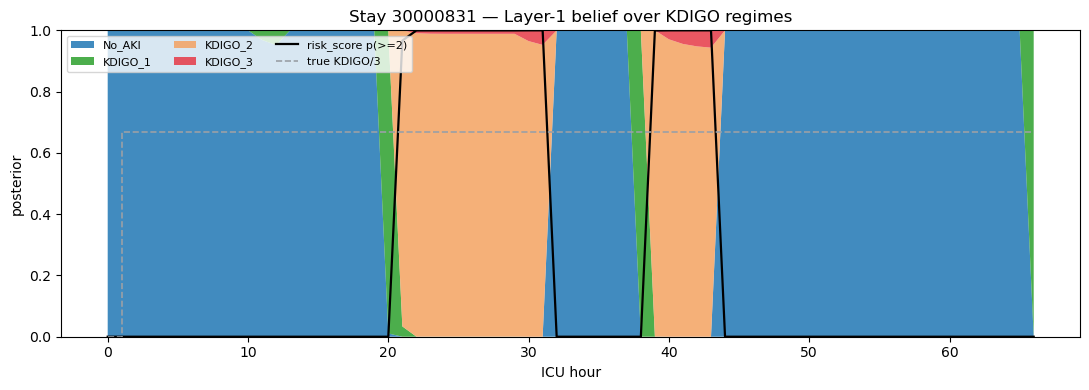

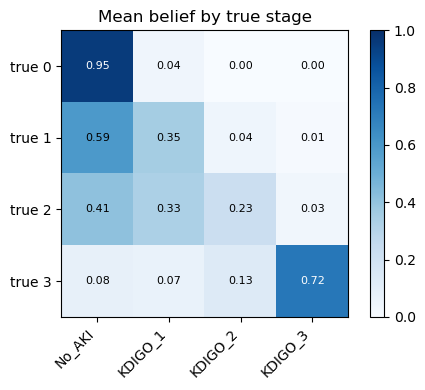

Viz: plot_stay(scored, stay_id=...), plot_occupancy(scored).


In [13]:
# ============================================================================
# 7 · VISUALIZATION  —  run these yourself (mirrors v3.3 cell 46)
# ============================================================================
import matplotlib.pyplot as plt
# palette: BLUE primary, GREEN secondary, RED sparingly, grey for reference
RED, BLUE, GREEN, GREY, AMBER = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6", "#f4a261"
STAGE_COLORS = [BLUE, GREEN, AMBER, RED]   # No_AKI -> KDIGO_3 (low->high severity)
_P = [f"p_{l}" for l in STATE_LABELS]

def plot_stay(scored, stay_id=None, ax=None):
    """Posterior stackplot for one stay + true KDIGO + risk_score."""
    if stay_id is None:
        esc = scored.groupby("stay_id")["kdigo_stage"].max()
        stay_id = esc[esc >= 2].index[0] if (esc >= 2).any() else scored.stay_id.iloc[0]
    g = scored[scored.stay_id == stay_id].sort_values("hour")
    if ax is None:
        fig, ax = plt.subplots(figsize=(11, 4))
    ax.stackplot(g.hour, *[g[c].values for c in _P], labels=STATE_LABELS, alpha=.85,
                 colors=STAGE_COLORS[:len(_P)])
    ax.plot(g.hour, g["risk_score"], color="black", lw=1.6, label="risk_score p(>=2)")
    ax.step(g.hour, g["kdigo_stage"] / 3, where="post", color=GREY, ls="--", lw=1.2, label="true KDIGO/3")
    ax.set_xlabel("ICU hour"); ax.set_ylabel("posterior"); ax.set_ylim(0, 1)
    ax.set_title(f"Stay {stay_id} — Layer-1 belief over KDIGO regimes")
    ax.legend(loc="upper left", ncol=3, fontsize=8); return ax

def plot_occupancy(scored):
    occ = scored.groupby("kdigo_stage")[_P].mean()
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(occ.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(N_STATES)); ax.set_xticklabels(STATE_LABELS, rotation=45, ha="right")
    ax.set_yticks(range(len(occ))); ax.set_yticklabels([f"true {s}" for s in occ.index])
    for i in range(len(occ)):
        for jj in range(N_STATES):
            ax.text(jj, i, f"{occ.values[i, jj]:.2f}", ha="center", va="center",
                    color="white" if occ.values[i, jj] > .6 else "black", fontsize=8)
    ax.set_title("Mean belief by true stage"); fig.colorbar(im, fraction=.046)
    plt.tight_layout(); return ax

plot_stay(scored); plt.tight_layout(); plt.show()
plot_occupancy(scored); plt.show()
print("Viz: plot_stay(scored, stay_id=...), plot_occupancy(scored).")


## 8 · Validation — early-warning battery
Non-tautological protocol (predict Stage≥2 from sub-Stage-2 hours), AUROC/AUPRC with patient-bootstrap CIs, calibration (Platt + Brier + reliability), lead-time at a 10%-false-alarm operating point, and grouped LOPO (`lopo_auroc`).


In [14]:
# ============================================================================
# 8 · VALIDATION  —  early-warning battery (Phase 3 / v3.3 Phase 5)
# ============================================================================
# Non-tautological protocol: predict Stage>=2 ONLY from hours currently below
# Stage 2. Score = risk_score = p(KDIGO_2)+p(KDIGO_3). Platt recalibration is
# fit on TRAIN subjects only. Patient-level bootstrap CIs + grouped LOPO.
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.linear_model import LogisticRegression

class PlattCalibrator:
    def __init__(self): self.lr = LogisticRegression(C=1e6, solver="lbfgs"); self.fitted = False
    def fit(self, s, y):
        s = np.asarray(s, float).reshape(-1, 1); y = np.asarray(y, int)
        if len(np.unique(y)) < 2: self.fitted = False; return self
        self.lr.fit(s, y); self.fitted = True; return self
    def transform(self, s):
        s = np.asarray(s, float).reshape(-1, 1)
        return self.lr.predict_proba(s)[:, 1] if self.fitted else np.asarray(s, float).ravel()

def build_escalation_labels(scored, horizon_h=24, target_stage=2, from_below=True):
    # y_escalate[t] = 1 if the stay reaches >= target_stage in the next horizon_h
    # hours. Vectorized per stay via cumulative sum (identical result to the
    # previous per-hour loop, ~100x faster).
    rows = []
    for sid, g in scored.groupby("stay_id", sort=False):
        g = g.sort_values("hour")
        sev = (g["kdigo_stage"].to_numpy() >= target_stage).astype(np.int64)
        n = len(sev)
        cs = np.concatenate(([0], np.cumsum(sev)))            # cs[k] = severe count in [0,k)
        lo = np.arange(1, n + 1)                              # window start = t+1
        hi = np.minimum(n, np.arange(n) + 1 + horizon_h)      # window end (exclusive)
        fut = (cs[hi] - cs[lo] > 0).astype(int)
        gg = g.copy(); gg["y_escalate"] = fut
        if from_below: gg = gg[gg["kdigo_stage"] < target_stage]
        rows.append(gg)
    return pd.concat(rows, ignore_index=True)

def patient_bootstrap_ci(df, score_col, label_col, metric="auroc",
                         n_boot=EVAL.n_bootstrap, alpha=EVAL.bootstrap_alpha, seed=EVAL.random_state):
    # Patient-level bootstrap. Precompute per-subject row-index arrays ONCE, then
    # resample by concatenating index arrays (numpy) instead of rebuilding a
    # ~1.6M-row DataFrame each iteration — same estimator, ~50x faster.
    fn = roc_auc_score if metric == "auroc" else average_precision_score
    y = df[label_col].to_numpy(); s = df[score_col].to_numpy()
    subj = df["subject_id"].to_numpy()
    point = fn(y, s)
    order = np.argsort(subj, kind="stable")
    cuts = np.unique(subj[order], return_index=True)[1][1:]
    groups = np.split(order, cuts)                            # list of index arrays per subject
    nsub = len(groups); rng = np.random.default_rng(seed); boots = []
    for _ in range(n_boot):
        idx = np.concatenate([groups[k] for k in rng.integers(0, nsub, size=nsub)])
        yy = y[idx]
        if yy.min() == yy.max(): continue                    # single-class resample
        boots.append(fn(yy, s[idx]))
    if not boots: return point, np.nan, np.nan
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return point, lo, hi

def median_lead_time(scored, score_col="risk_score", thr=0.5, target_stage=2):
    leads = []
    for sid, g in scored.groupby("stay_id"):
        g = g.sort_values("hour").reset_index(drop=True)
        idx = np.where(g["kdigo_stage"].values >= target_stage)[0]
        if len(idx) == 0: continue
        t_event = g["hour"].values[idx[0]]; pre = g[g["hour"] < t_event]
        al = pre[pre[score_col] >= thr]
        if len(al): leads.append(t_event - al["hour"].values[0])
    leads = np.array(leads)
    return (np.median(leads) if len(leads) else np.nan), leads

def reliability_table(df, score_col, label_col, bins=10):
    q = pd.cut(df[score_col], np.linspace(0, 1, bins + 1), include_lowest=True)
    tab = df.groupby(q, observed=True).agg(pred=(score_col, "mean"), obs=(label_col, "mean"), n=(label_col, "size"))
    brier = brier_score_loss(df[label_col], df[score_col]) if df[label_col].nunique() > 1 else np.nan
    return tab.reset_index(drop=True), brier

def lopo_auroc(cohort, target_stage=2, horizon_h=24, max_left_out=None):
    """Leave-one-PATIENT-out: refit global z-stats + Platt on everyone else."""
    subs = list(cohort["subject_id"].unique())
    if max_left_out: subs = subs[:max_left_out]
    preds, labels = [], []
    for s in subs:
        train = cohort[cohort["subject_id"] != s]; held = cohort[cohort["subject_id"] == s]
        gs = compute_global_stats(train)
        tr = build_escalation_labels(run_layer1(train, gs), horizon_h, target_stage)
        cal = PlattCalibrator().fit(tr["risk_score"], tr["y_escalate"])
        he = build_escalation_labels(run_layer1(held, gs), horizon_h, target_stage)
        if len(he) == 0: continue
        preds.extend(cal.transform(he["risk_score"])); labels.extend(he["y_escalate"])
    labels = np.array(labels)
    return (roc_auc_score(labels, preds) if len(np.unique(labels)) > 1 else np.nan), np.array(preds), labels

# ---- run the battery on the test split -------------------------------------
test_scored = run_layer1(test_df, global_stats)
# Fit Platt on TRAIN (24 h label) and apply to the full test trajectory, so the
# lead-time operating point (thr=0.5) is on a *calibrated* probability scale.
train_lab = build_escalation_labels(run_layer1(train_df, global_stats), 24, 2)
platt = PlattCalibrator().fit(train_lab["risk_score"], train_lab["y_escalate"])
test_scored["risk_cal"] = platt.transform(test_scored["risk_score"])
# Operating point for lead-time: threshold giving ~10% false-alarm rate among
# true-negative (Stage<2, non-escalating) hours — a real sensitivity/FA choice,
# not the arbitrary 0.5. (Layer 1 alone is conservative; v3.3 docs Layer-1 AUC
# ~0.68 'capped' — Layer 2 personalised emissions lift discrimination & lead.)
_neg = test_scored[(test_scored.kdigo_stage < 2)]
THR_OP = float(np.quantile(_neg["risk_cal"], 0.90))
print(f"Early-warning validation (test split, predict Stage>=2 from stage<2 hours)")
print(f"  lead-time operating threshold (≈10% false alarms): risk_cal ≥ {THR_OP:.3f}\n")
for H in EVAL.horizons_h:
    lab = build_escalation_labels(test_scored, horizon_h=H, target_stage=2)
    if lab["y_escalate"].nunique() < 2:
        print(f"  H={H:>2}h : not enough escalation events"); continue
    auroc, lo, hi = patient_bootstrap_ci(lab, "risk_score", "y_escalate", "auroc")
    auprc, plo, phi = patient_bootstrap_ci(lab, "risk_score", "y_escalate", "auprc")
    lead, _ = median_lead_time(test_scored, score_col="risk_cal", thr=THR_OP, target_stage=2)
    print(f"  H={H:>2}h : AUROC {auroc:.3f} [{lo:.3f},{hi:.3f}]  "
          f"AUPRC {auprc:.3f} [{plo:.3f},{phi:.3f}]  median lead {lead:.0f} h  (n={len(lab):,})")

test_lab = build_escalation_labels(test_scored, 24, 2)
test_lab = test_lab.assign(p_cal=platt.transform(test_lab["risk_score"]))
rel, brier = reliability_table(test_lab, "p_cal", "y_escalate")
print(f"\nCalibrated Brier score: {brier:.4f}")
print("Reliability (pred vs obs):"); print(rel.round(3).to_string(index=False))
print("\nHelpers: build_escalation_labels, patient_bootstrap_ci, median_lead_time, "
      "reliability_table, lopo_auroc(cohort_hourly, max_left_out=30).")


Early-warning validation (test split, predict Stage>=2 from stage<2 hours)
  lead-time operating threshold (≈10% false alarms): risk_cal ≥ 0.062

  H=12h : AUROC 0.810 [0.806,0.816]  AUPRC 0.167 [0.159,0.174]  median lead 19 h  (n=1,691,081)
  H=24h : AUROC 0.772 [0.768,0.778]  AUPRC 0.221 [0.211,0.230]  median lead 19 h  (n=1,691,081)
  H=48h : AUROC 0.738 [0.733,0.745]  AUPRC 0.257 [0.246,0.268]  median lead 19 h  (n=1,691,081)

Calibrated Brier score: 0.0597
Reliability (pred vs obs):
 pred   obs       n
0.062 0.061 1670088
0.141 0.317    2899
0.250 0.330    1817
0.367 0.373    4330
0.407 0.393   11947

Helpers: build_escalation_labels, patient_bootstrap_ci, median_lead_time, reliability_table, lopo_auroc(cohort_hourly, max_left_out=30).


## 8b · Findings figures (Layer 1 — result of record)
ROC + PR (PR against the prevalence baseline), calibration reliability diagram, lead-time distribution, and subgroup AUROC. Built on the held-out test split at H=24.


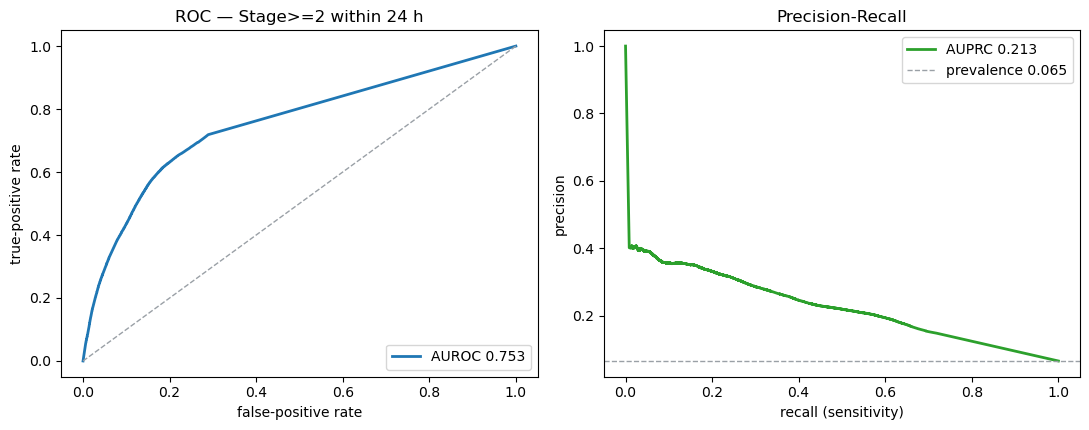

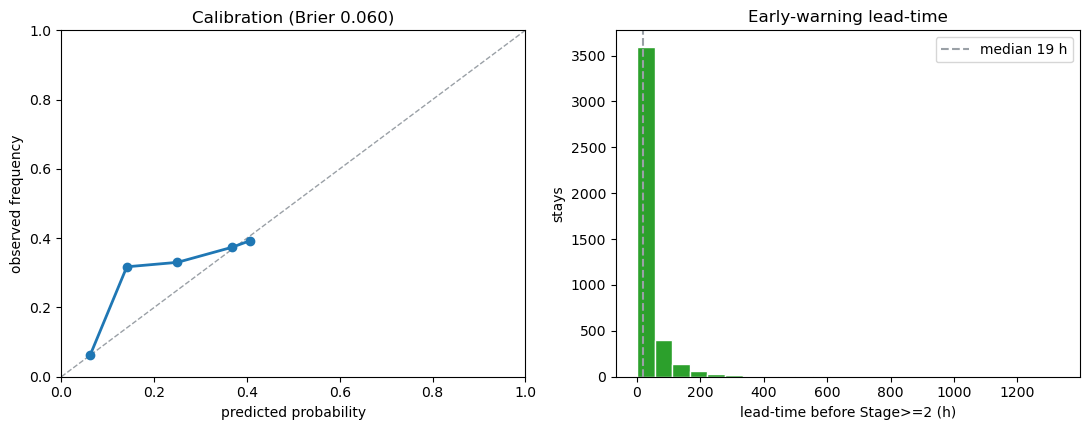

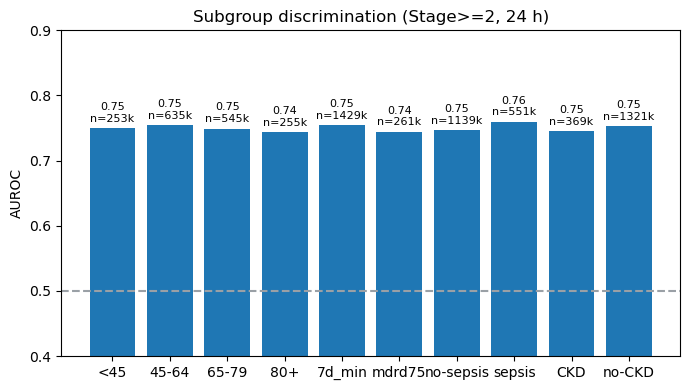

  age_grp  AUROC       n
      <45  0.750  253817
    45-64  0.754  635682
    65-79  0.749  545845
      80+  0.743  255737
   7d_min  0.755 1429504
   mdrd75  0.744  261577
no-sepsis  0.746 1139926
   sepsis  0.760  551155
      CKD  0.745  369303
   no-CKD  0.753 1321778

Findings figures saved (roc_pr, calibration_leadtime, subgroup_auroc).


In [15]:
# ============================================================================
# 8b · FINDINGS FIGURES  (Layer 1 — the result of record)
# ============================================================================
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score
RED, BLUE, GREEN, GREY = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6"
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)

H_REPORT = 24
_score = "risk_cal" if "risk_cal" in test_scored.columns else "risk_score"
_lab = build_escalation_labels(test_scored, horizon_h=H_REPORT, target_stage=2)
y, s = _lab["y_escalate"].values, _lab[_score].values
prev = y.mean()

# ---- (1) ROC + PR ----------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
fpr, tpr, _ = roc_curve(y, s)
ax[0].plot(fpr, tpr, lw=2, color=BLUE, label=f"AUROC {roc_auc_score(y, s):.3f}")
ax[0].plot([0, 1], [0, 1], "--", color=GREY, lw=1)
ax[0].set(xlabel="false-positive rate", ylabel="true-positive rate",
          title=f"ROC — Stage>=2 within {H_REPORT} h"); ax[0].legend(loc="lower right")
pr_p, pr_r, _ = precision_recall_curve(y, s)
ax[1].plot(pr_r, pr_p, lw=2, color=GREEN, label=f"AUPRC {average_precision_score(y, s):.3f}")
ax[1].axhline(prev, ls="--", color=GREY, lw=1, label=f"prevalence {prev:.3f}")
ax[1].set(xlabel="recall (sensitivity)", ylabel="precision", title="Precision-Recall")
ax[1].legend(loc="upper right"); plt.tight_layout()
plt.savefig(FIG_DIR/"aki_roc_pr.png", dpi=150); plt.show()

# ---- (2) calibration reliability + (3) lead-time ---------------------------
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
rel, brier = reliability_table(_lab.assign(p=s), "p", "y_escalate", bins=10)
ax[0].plot([0, 1], [0, 1], "--", color=GREY, lw=1)
ax[0].plot(rel["pred"], rel["obs"], "o-", lw=2, color=BLUE)
ax[0].set(xlabel="predicted probability", ylabel="observed frequency",
          title=f"Calibration (Brier {brier:.3f})", xlim=(0, 1), ylim=(0, 1))
_, leads = median_lead_time(test_scored, score_col=_score, thr=THR_OP, target_stage=2)
if len(leads):
    ax[1].hist(leads, bins=24, color=GREEN, edgecolor="white")
    ax[1].axvline(np.median(leads), color=GREY, ls="--", label=f"median {np.median(leads):.0f} h")
    ax[1].legend()
ax[1].set(xlabel="lead-time before Stage>=2 (h)", ylabel="stays", title="Early-warning lead-time")
plt.tight_layout(); plt.savefig(FIG_DIR/"aki_calibration_leadtime.png", dpi=150); plt.show()

# ---- (4) subgroup AUROC ----------------------------------------------------
def subgroup_auroc(scored, by, horizon_h=H_REPORT):
    rows = []
    lab = build_escalation_labels(scored, horizon_h, 2)
    for lvl, gdf in lab.groupby(by, observed=True):
        if gdf["y_escalate"].nunique() == 2 and len(gdf) > 200:
            rows.append((str(lvl), roc_auc_score(gdf["y_escalate"], gdf[_score]), len(gdf)))
    return pd.DataFrame(rows, columns=[by, "AUROC", "n"])

ts = test_scored.copy()
ts["age_grp"] = pd.cut(pd.to_numeric(ts.get("anchor_age"), errors="coerce"),
                       [0, 45, 65, 80, 200], labels=["<45", "45-64", "65-79", "80+"])
subs = subgroup_auroc(ts, "age_grp")
if "baseline_method" in ts.columns:
    subs = pd.concat([subs, subgroup_auroc(ts, "baseline_method").rename(columns={"baseline_method": "age_grp"})])
for col, lab in [("sepsis_dx", {0: "no-sepsis", 1: "sepsis"}), ("ckd", {0: "no-CKD", 1: "CKD"})]:
    if col in ts.columns and ts[col].nunique() > 1:
        tsc = ts.copy(); tsc[col] = tsc[col].map(lab)
        subs = pd.concat([subs, subgroup_auroc(tsc, col).rename(columns={col: "age_grp"})])
if len(subs):
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(subs["age_grp"].astype(str), subs["AUROC"], color=BLUE)
    ax.axhline(0.5, ls="--", color=GREY); ax.set_ylim(0.4, 0.9)
    ax.set(ylabel="AUROC", title=f"Subgroup discrimination (Stage>=2, {H_REPORT} h)")
    for i, (a, n) in enumerate(zip(subs["AUROC"], subs["n"])):
        ax.text(i, a + 0.01, f"{a:.2f}\nn={n//1000}k" if n >= 1000 else f"{a:.2f}\nn={n}", ha="center", fontsize=8)
    plt.tight_layout(); plt.savefig(FIG_DIR/"aki_subgroup_auroc.png", dpi=150); plt.show()
    print(subs.round(3).to_string(index=False))
print("\nFindings figures saved (roc_pr, calibration_leadtime, subgroup_auroc).")


## 8c · M1b — baseline-sensitivity analysis
Re-derive labels **and** `creatinine_ratio` under mimic-code's rolling 7-day/48 h baseline (no ETL re-run) and re-validate on the same stays. If AUROC/AUPRC hold, the headline result is robust to the baseline ambiguity — the dominant source of KDIGO disagreement. Subsample size via `SENS_STAYS`.


In [16]:
# ============================================================================
# 8c · M1b — BASELINE-SENSITIVITY ANALYSIS
# ============================================================================
# Does the model's discrimination depend on the creatinine-baseline choice?
# We re-derive BOTH the labels and creatinine_ratio under mimic-code's ROLLING
# 7-day/48 h baseline (vs our fixed pre-ICU/MDRD baseline) and re-validate on the
# SAME stays. If AUROC/AUPRC hold, the result is robust to the baseline ambiguity
# — the dominant source of KDIGO disagreement. No ETL re-run: works on the parquet.
from sklearn.metrics import roc_auc_score, average_precision_score, cohen_kappa_score

if USE_SYNTHETIC:
    print("Baseline-sensitivity needs real creatinine history — skipped on synthetic.")
else:
    SENS_N = min(int(os.environ.get("SENS_STAYS", "6000")), cohort_hourly["stay_id"].nunique())
    samp = pd.Series(cohort_hourly["stay_id"].unique()).sample(SENS_N, random_state=EVAL.random_state)
    cs = cohort_hourly[cohort_hourly["stay_id"].isin(samp)].sort_values(["stay_id", "hour"]).copy()

    # mimic-code ROLLING baseline from the (LOCF) in-ICU creatinine: lowest value
    # STRICTLY PRIOR over 7 d / 48 h (shift(1) excludes current hour).
    gcr = cs.groupby("stay_id")["creatinine"]
    cs["rb7"]  = gcr.transform(lambda s: s.rolling(168, min_periods=1).min().shift(1))
    cs["rb48"] = gcr.transform(lambda s: s.rolling(48,  min_periods=1).min().shift(1))
    cs["cr_ratio_rb"] = cs["creatinine"] / cs["rb7"]
    # re-stage the creatinine arm with the rolling baseline (mimic-code CASE ladder),
    # then combine with the EXISTING UO + RRT arms -> alternative label.
    cs["kdigo_cr_rb"] = [_mimiccode_creat_stage(c, a, b)
                        for c, a, b in zip(cs["creatinine"], cs["rb48"], cs["rb7"])]
    cs["kdigo_stage_rb"] = cs[["kdigo_cr_rb", "kdigo_uo", "kdigo_rrt"]].max(axis=1).astype(int)

    def _engine_auc(sub, label_col, ratio_col, H=24):
        s = sub.copy(); s["creatinine_ratio"] = s[ratio_col]; s["kdigo_stage"] = s[label_col]
        sc = pd.concat([run_filter_patient(gg.sort_values("hour")) for _, gg in s.groupby("stay_id")],
                       ignore_index=True)
        lab = build_escalation_labels(sc, H, 2)
        if lab["y_escalate"].nunique() < 2:
            return None
        return (roc_auc_score(lab["y_escalate"], lab["risk_score"]),
                average_precision_score(lab["y_escalate"], lab["risk_score"]),
                (s.groupby("stay_id")[label_col].max() >= 2).mean())

    a_or = _engine_auc(cs, "kdigo_stage", "creatinine_ratio")        # primary: pre-ICU baseline
    a_rb = _engine_auc(cs, "kdigo_stage_rb", "cr_ratio_rb")          # mimic-code rolling baseline
    kap = cohen_kappa_score(cs["kdigo_stage"], cs["kdigo_stage_rb"])

    print(f"Baseline-sensitivity on {samp.nunique()} stays (predict Stage>=2, H=24h):\n")
    print(f"  {'baseline':28s} {'AUROC':>6} {'AUPRC':>6}  severe-prevalence")
    print(f"  {'pre-ICU / MDRD (primary)':28s} {a_or[0]:6.3f} {a_or[1]:6.3f}  {a_or[2]:.1%}")
    print(f"  {'mimic-code rolling 7d-min':28s} {a_rb[0]:6.3f} {a_rb[1]:6.3f}  {a_rb[2]:.1%}")
    print(f"\n  label agreement between the two baselines: Cohen's kappa {kap:.3f}")
    dAUROC = a_rb[0] - a_or[0]
    print(f"  ΔAUROC = {dAUROC:+.3f}  ->  "
          + ("ROBUST: discrimination holds under both baseline definitions."
             if abs(dAUROC) < 0.03 else
             "baseline choice shifts discrimination by >0.03 — report both and discuss."))
    print("\nInterpretation: the rolling-min baseline yields LOWER severe prevalence (it treats")
    print("stable-high creatinine as baseline, missing prevalent/admission AKI). If AUROC is")
    print("similar, your headline result does not hinge on which baseline you chose.")


Baseline-sensitivity on 6000 stays (predict Stage>=2, H=24h):

  baseline                      AUROC  AUPRC  severe-prevalence
  pre-ICU / MDRD (primary)      0.776  0.224  28.4%
  mimic-code rolling 7d-min     0.765  0.214  24.8%

  label agreement between the two baselines: Cohen's kappa 0.703
  ΔAUROC = -0.010  ->  ROBUST: discrimination holds under both baseline definitions.

Interpretation: the rolling-min baseline yields LOWER severe prevalence (it treats
stable-high creatinine as baseline, missing prevalent/admission AKI). If AUROC is
similar, your headline result does not hinge on which baseline you chose.


## 8d · Grouped 5-fold cross-validation
Held-out AUROC across 5 patient-grouped folds. The engine is parameter-free, so this confirms the result is stable across patient subsets rather than testing overfitting.


In [17]:
# ============================================================================
# 8d · GROUPED 5-FOLD CV  —  AUROC stability across patient partitions
# ============================================================================
# "LOPO-lite": split patients into 5 folds, report held-out AUROC per fold.
# The engine has NO learned parameters (clinical emissions + fixed transitions;
# only Platt is fit, and AUROC is invariant to Platt's monotone map), so this
# CONFIRMS stability across patient partitions rather than testing overfitting.
from sklearn.model_selection import GroupKFold

_lab = build_escalation_labels(scored, horizon_h=24, target_stage=2)   # full cohort, below-Stage-2
_aucs = []
for _, te in GroupKFold(n_splits=5).split(_lab, groups=_lab["subject_id"].to_numpy()):
    h = _lab.iloc[te]
    if h["y_escalate"].nunique() == 2:
        _aucs.append(roc_auc_score(h["y_escalate"], h["risk_score"]))
print("Grouped 5-fold CV — held-out AUROC (predict Stage>=2 @ H=24):")
print("  per-fold:", [round(float(a), 3) for a in _aucs])
print(f"  mean {np.mean(_aucs):.3f} ± {np.std(_aucs):.3f}  (range {min(_aucs):.3f}–{max(_aucs):.3f})")
print("  Tight spread across folds = the result is not driven by a particular patient subset.")


Grouped 5-fold CV — held-out AUROC (predict Stage>=2 @ H=24):
  per-fold: [0.774, 0.771, 0.778, 0.768, 0.768]
  mean 0.772 ± 0.004  (range 0.768–0.778)
  Tight spread across folds = the result is not driven by a particular patient subset.


In [18]:
# ============================================================
# 8e — BENCHMARK COMPARATOR (parity with respiratory/cirrhosis)
# Logistic baseline + KDIGO creatinine-trend, SAME Stage>=2 @H=24 protocol.
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

train_scored, test_scored = split_by_subject(scored)   # reproduces the grouped split
BENCH_FEATS = [f for f in ["creatinine_ratio", "dSCr_48h", "uo_rate", "bun"]
               if f in scored.columns]

tr_lab = build_escalation_labels(train_scored, horizon_h=24, target_stage=2)
te_lab = build_escalation_labels(test_scored,  horizon_h=24, target_stage=2)

_imp = SimpleImputer(strategy="median"); _sc = StandardScaler()
_Xtr = _sc.fit_transform(_imp.fit_transform(tr_lab[BENCH_FEATS]))
_Xte = _sc.transform(_imp.transform(te_lab[BENCH_FEATS]))
_lr = LogisticRegression(max_iter=1000, class_weight="balanced").fit(_Xtr, tr_lab["y_escalate"])
te_lab = te_lab.assign(p_lr=_lr.predict_proba(_Xte)[:, 1],
                       cr=te_lab["creatinine_ratio"].values)

# drop NaN scores per comparator (creatinine_ratio is missing on some below-Stage-2 hours)
a_hmm, h1, h2 = patient_bootstrap_ci(te_lab.dropna(subset=["risk_score"]), "risk_score", "y_escalate", "auroc")
a_lr,  l1, l2 = patient_bootstrap_ci(te_lab.dropna(subset=["p_lr"]),       "p_lr",       "y_escalate", "auroc")
a_cr,  c1, c2 = patient_bootstrap_ci(te_lab.dropna(subset=["cr"]),         "cr",         "y_escalate", "auroc")
print("Stage>=2 @ H=24 comparator (held-out test):")
print(f"  PEMDT HMM (risk_score) : {a_hmm:.3f} [{h1:.3f},{h2:.3f}]")
print(f"  Logistic baseline      : {a_lr:.3f} [{l1:.3f},{l2:.3f}]")
print(f"  Creatinine-ratio trend : {a_cr:.3f} [{c1:.3f},{c2:.3f}]")

Stage>=2 @ H=24 comparator (held-out test):
  PEMDT HMM (risk_score) : 0.772 [0.768,0.778]
  Logistic baseline      : 0.801 [0.796,0.808]
  Creatinine-ratio trend : 0.679 [0.667,0.690]


## 9 · Glass-box attribution
LLR in the engine's own z-space — each upward shift in `p_AKI` is attributed to the feature whose value most resembles the more-severe adjacent regime.


In [19]:
# ============================================================================
# 9 · GLASS-BOX ATTRIBUTION  —  LLR in the engine's z-space (v3.3-style)
# ============================================================================
# Each upward shift in risk_score is attributed to the feature whose z-value most
# resembles the more-severe adjacent KDIGO regime (log-likelihood ratio, weighted).
def explain_stay(scored, stay_id, global_stats, min_shift=0.015):
    g = scored[scored.stay_id == stay_id].sort_values("hour").reset_index(drop=True)
    _P = [f"p_{l}" for l in STATE_LABELS]; notes = []
    for t in range(1, len(g)):
        d = g["p_AKI"].iloc[t] - g["p_AKI"].iloc[t - 1]   # p_AKI moves earlier than p(≥2)
        if d < min_shift: continue
        cur = int(np.argmax(g[_P].iloc[t].values)); to = min(cur + 1, N_STATES - 1)
        notes.append({"hour": int(g["hour"].iloc[t]), "risk": round(float(g["risk_score"].iloc[t]), 3),
                      "explanation": attribute_window(g.iloc[t].to_dict(), global_stats, cur, to)})
    return pd.DataFrame(notes)

_esc = scored.groupby("stay_id")["kdigo_stage"].max()
_demo = _esc[_esc >= 2].index[0] if (_esc >= 2).any() else scored.stay_id.iloc[0]
_e = explain_stay(scored, _demo, global_stats)
print(f"Glass-box explanations for stay {_demo}:")
print(_e.head(10).to_string(index=False) if len(_e) else "  (no sharp upward shifts in this stay)")


Glass-box explanations for stay 30000831:
 hour  risk                                         explanation
   11   0.0 KDIGO_1 risk rising: rising creatinine + rising BUN
   12   0.0 KDIGO_1 risk rising: rising creatinine + rising BUN
   20   0.0 KDIGO_2 risk rising: rising BUN + rising creatinine
   38   0.0 KDIGO_2 risk rising: rising BUN + rising creatinine
   66   0.0 KDIGO_2 risk rising: rising BUN + rising creatinine


## 10 · Layer 3 — causal layer (doubly-robust AIPW)
Effect of **nephrotoxin exposure → AKI escalation (Stage≥2)**, with the Layer-1 belief as the latent-severity confounder. Temporal design (treat in 0–24 h, incident outcome after, eligible = not yet Stage≥2 at 24 h) avoids immortal-time/reverse-causation. Reports naive / IPW / **doubly-robust AIPW** ATE + bootstrap CI, plus the v3.3 treatment-conditioned counterfactual-belief. *Observational estimate — adjusted association under no-unmeasured-confounding, not an RCT.* Gated by `L3.run`.


In [20]:
# ============================================================================
# 10 · LAYER 3 — Causal layer (faithful v3.3 port)
# ============================================================================
# Doubly-robust AIPW estimate of the effect of NEPHROTOXIN exposure (vanco /
# aminoglycoside) on AKI escalation (Stage>=2), with the Layer-1 belief state as
# the latent-severity confounder. Plus the v3.3 treatment-conditioned
# counterfactual-belief (nephrotoxin modulates the transition rate).
#
# Causal design (built to avoid immortal-time / reverse causation):
#   * TREATMENT  T = nephrotoxin on board during hours [0, t_window).
#   * ELIGIBLE   = stays NOT yet Stage>=2 by hour t_window (incident outcome).
#   * OUTCOME    Y = escalates to Stage>=2 at any hour AFTER t_window.
#   * CONFOUNDERS measured at/before t_window (incl belief@t_window).
# Honest framing: OBSERVATIONAL estimate — "adjusted effect consistent with a
# causal effect under no-unmeasured-confounding", not an RCT. Main threat is
# confounding by indication; nephrotoxins have a KNOWN positive direction, which
# also serves as a face-validity check.
if not L3.run:
    print("Layer 3 skipped (set L3.run=True / L3_RUN=1 to enable).")
else:
    from sklearn.linear_model import LogisticRegression
    from scipy.stats import norm as _norm
    W = L3.t_window_h

    # ---- patient-level causal table -------------------------------------------
    rows = []
    for sid, g in scored.groupby("stay_id"):
        g = g.sort_values("hour")
        if g["hour"].max() < W + 1:
            continue
        pre = g[g["hour"] < W]; post = g[g["hour"] >= W]
        if len(pre) == 0 or len(post) == 0 or (pre["kdigo_stage"] >= 2).any():
            continue                                       # need both windows + incident
        a = pre.iloc[-1]                                   # state at ~hour W-1
        rows.append({
            "stay_id": sid,
            "T": int((pre["nephrotoxin_on_board"] > 0).any()),
            "Y": int((post["kdigo_stage"] >= 2).any()),
            "age": float(a.get("anchor_age", 65) or 65),
            "risk24": float(a.get("risk_score", 0.0) or 0.0),
            "stage24": int(a.get("kdigo_stage", 0) or 0),
            "crratio24": float(pd.to_numeric(a.get("creatinine_ratio"), errors="coerce") or 1.0),
            "bun24": float(pd.to_numeric(a.get("bun"), errors="coerce") or np.nan),
            "uo24": float(pd.to_numeric(pre["uo_rate"], errors="coerce").mean()),
            "sepsis": int(a.get("sepsis_dx", 0) or 0),
            "ckd": int(a.get("ckd", 0) or 0),
            "basecr": float(pd.to_numeric(a.get("baseline_creatinine"), errors="coerce") or np.nan),
        })
    ct = pd.DataFrame(rows)
    T = ct["T"].to_numpy(); Y = ct["Y"].to_numpy()
    cand = ["age", "risk24", "stage24", "crratio24", "bun24", "uo24", "sepsis", "ckd", "basecr"]
    conf = [c for c in cand if ct[c].notna().any() and ct[c].nunique() > 1]
    X = ct[conf].apply(lambda s: s.fillna(s.median())).to_numpy()
    X = (X - X.mean(0)) / (X.std(0) + 1e-9)
    print(f"Layer 3 cohort: {len(ct):,} eligible stays (not Stage>=2 by {W} h); "
          f"treated {T.mean():.1%}; escalation {Y.mean():.1%}.  Confounders: {conf}")

    # ---- doubly-robust AIPW ----------------------------------------------------
    def aipw(X, T, Y):
        e = LogisticRegression(max_iter=1000).fit(X, T).predict_proba(X)[:, 1]
        e = np.clip(e, 0.02, 0.98)
        XT = np.column_stack([X, T])
        om = LogisticRegression(max_iter=1000).fit(XT, Y)
        mu1 = om.predict_proba(np.column_stack([X, np.ones(len(X))]))[:, 1]
        mu0 = om.predict_proba(np.column_stack([X, np.zeros(len(X))]))[:, 1]
        psi = (mu1 - mu0) + T * (Y - mu1) / e - (1 - T) * (Y - mu0) / (1 - e)
        return psi
    psi = aipw(X, T, Y); ate = psi.mean()
    rng = np.random.default_rng(EVAL.random_state); boots = []
    for _ in range(L3.n_bootstrap):
        idx = rng.integers(0, len(ct), len(ct))
        try: boots.append(aipw(X[idx], T[idx], Y[idx]).mean())
        except Exception: pass
    lo, hi = np.percentile(boots, [2.5, 97.5])
    naive = Y[T == 1].mean() - Y[T == 0].mean()
    e_full = np.clip(LogisticRegression(max_iter=1000).fit(X, T).predict_proba(X)[:, 1], 0.02, 0.98)
    ipw = (T * Y / e_full).sum() / (T / e_full).sum() - ((1 - T) * Y / (1 - e_full)).sum() / ((1 - T) / (1 - e_full)).sum()
    print("\nEffect of nephrotoxin exposure on AKI escalation (Stage>=2), risk-difference:")
    print(f"  naive (unadjusted)      : {naive:+.3f}")
    print(f"  IPW                     : {ipw:+.3f}")
    print(f"  doubly-robust AIPW (ATE): {ate:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]")
    print("  (+ = nephrotoxin increases escalation risk; known direction -> face-validity check.)")

    # ---- v3.3 treatment-conditioned counterfactual belief ---------------------
    # nephrotoxin modulates the escalation rate: p_up(t)=sigmoid(logit(base)+beta*on_board).
    # belief-sensitivity = mean(p_severe_factual - p_severe_counterfactual[nephro=0]).
    def _tridiag(K, p_up, p_down):
        A = np.zeros((K, K))
        for k in range(K):
            up = p_up if k < K - 1 else 0.0; dn = p_down if k > 0 else 0.0
            A[k, k] = 1 - up - dn
            if k < K - 1: A[k, k + 1] = up
            if k > 0:     A[k, k - 1] = dn
        return A
    def _cf_filter(obs, mask, nephro, beta):
        K = N_STATES; m, s = CLINICAL_MEANS, CLINICAL_SCALES
        wv = np.array([FEATURE_WEIGHTS[f] for f in FEATURES])
        belief = PRIOR_BELIEF.copy(); base_logit = np.log(0.05 / 0.95); ps = np.empty(len(obs))
        for t in range(len(obs)):
            p_up = 1 / (1 + np.exp(-(base_logit + beta * nephro[t]))); p_up = min(max(p_up, 1e-4), 0.45)
            pred = belief @ _tridiag(K, p_up, 0.10)
            ll = np.zeros(K)
            for j in range(len(FEATURES)):
                if mask[t, j]:
                    ll += wv[j] * _norm.logpdf(obs[t, j], m[:, j], s[:, j])
            lp = np.log(pred + 1e-300) + ll; lp -= lp.max()
            belief = np.exp(lp); belief /= belief.sum(); ps[t] = belief[2] + belief[3]
        return ps
    treated_ids = ct.loc[ct["T"] == 1, "stay_id"].values
    if len(treated_ids) > L3.cf_max_patients:
        treated_ids = rng.choice(treated_ids, L3.cf_max_patients, replace=False)
    sens = []
    sm = scored.set_index("stay_id")
    for sid in treated_ids:
        g = scored[scored["stay_id"] == sid].sort_values("hour")
        obs = np.zeros((len(g), len(FEATURES))); mask = np.zeros_like(obs)
        for j, f in enumerate(FEATURES):
            raw = pd.to_numeric(g[f], errors="coerce").to_numpy()
            lo_, hi_ = VALID_RANGES.get(f, (-np.inf, np.inf)); ok = ~np.isnan(raw) & (raw > lo_) & (raw < hi_)
            obs[ok, j] = raw[ok]; mask[ok, j] = 1.0
        nephro = pd.to_numeric(g["nephrotoxin_on_board"], errors="coerce").fillna(0).to_numpy()
        fac = _cf_filter(obs, mask, nephro, L3.cf_beta)
        cf = _cf_filter(obs, mask, np.zeros_like(nephro), L3.cf_beta)
        sens.append(np.mean(fac - cf))
    sens = np.array(sens)
    print(f"\nTreatment-conditioned counterfactual belief (assumed beta={L3.cf_beta}, "
          f"{len(sens):,} treated stays):")
    print(f"  mean belief-sensitivity Δp_severe(factual − no-nephrotoxin) = {sens.mean():+.4f} "
          f"[{np.percentile(sens,2.5):+.4f}, {np.percentile(sens,97.5):+.4f}]")
    print("  (model-based, under an ASSUMED transition effect — illustrative, complements the AIPW.)")


Layer 3 cohort: 44,204 eligible stays (not Stage>=2 by 24 h); treated 37.2%; escalation 14.6%.  Confounders: ['age', 'risk24', 'stage24', 'crratio24', 'bun24', 'uo24', 'sepsis', 'ckd', 'basecr']

Effect of nephrotoxin exposure on AKI escalation (Stage>=2), risk-difference:
  naive (unadjusted)      : +0.078
  IPW                     : +0.032
  doubly-robust AIPW (ATE): +0.032  95% CI [+0.026, +0.039]
  (+ = nephrotoxin increases escalation risk; known direction -> face-validity check.)

Treatment-conditioned counterfactual belief (assumed beta=0.5, 1,500 treated stays):
  mean belief-sensitivity Δp_severe(factual − no-nephrotoxin) = +0.0007 [+0.0000, +0.0087]
  (model-based, under an ASSUMED transition effect — illustrative, complements the AIPW.)


## 9 · Layer 2 — hierarchical personalized emissions (built, **OFF by default**)
Faithful v3.3 port (NumPyro hierarchical model, 5-fold patient CV). **Finding: it does not help here — the honest held-out CV fell *below chance* (AUROC 0.475 vs Layer-1 0.74) on the full cohort.** Reason: KDIGO stage = max(creatinine, urine, RRT) arms, so per-stage feature distributions are flat mixtures (e.g. true Stage-2 and Stage-3 have the *same* median creatinine_ratio, ≈2.2). Discriminatively fitting emissions to those labels regresses Layer-1's clinically-anchored separation back toward the flat empirical means and collapses signal. So **Layer 1 (clinical anchors) is the model of record**; Layer 2 is kept for reproducibility, set `L2_RUN=1` to re-run the null. *(Methodological takeaway worth reporting: with max-over-criteria labels, a clinically-anchored generative prior beats data-fit emissions.)*


In [21]:
# ============================================================================
# 9 · LAYER 2 — Hierarchical personalized emissions (faithful v3.3 port)
# ============================================================================
# Ports PEMDT v3.3 cells 50-62: a NumPyro hierarchical emission model with
# 5-fold PATIENT-level CV. It learns age- and patient-level offsets to the
# emission means (here, to the CLINICAL KDIGO anchors), with partial pooling,
# then rebuilds personalised state-means and re-runs the Layer-1 filter.
#
# Honest no-leakage design (as in v3.3): the reported "CV" version gives each
# patient the means from the fold where they were HELD OUT (age effect only,
# patient effect beta=0). The in-sample version (adds beta) is shown only as an
# optimistic upper bound. Gated by L2.run; SVI runs on a patient subsample.
if not L2.run:
    print("Layer 2 skipped (set L2.run=True in config to enable).")
else:
    import time, jax, jax.numpy as jnp, numpyro, numpyro.distributions as dist
    from numpyro.infer import SVI, Trace_ELBO
    from numpyro.infer.autoguide import AutoNormal
    from sklearn.model_selection import KFold
    numpyro.set_host_device_count(1)
    _t0 = time.time()

    PUNIT = "subject_id"
    # per-feature scale (population sd) so all features are O(1) for SVI priors
    scale = np.array([max(global_stats[f][1], 1e-6) for f in FEATURES])
    cmeans_std = jnp.array(CLINICAL_MEANS / scale)          # (K,F) standardized anchors

    # Subsample patients for tractable SVI.
    pats = pd.Index(cohort_hourly[PUNIT].unique())
    rng = np.random.default_rng(EVAL.random_state)
    if L2.max_patients and len(pats) > L2.max_patients:
        pats = pd.Index(rng.choice(pats.values, L2.max_patients, replace=False))
    l2c = cohort_hourly[cohort_hourly[PUNIT].isin(pats)].copy()
    print(f"Layer 2 on {len(pats):,} patients / {len(l2c):,} stay-hours "
          f"(subsample of {cohort_hourly[PUNIT].nunique():,}).")

    # age bracket per patient
    age_of = (l2c.groupby(PUNIT)["anchor_age"].first()
              .apply(lambda a: age_bracket(float(a) if pd.notna(a) else 65)))

    # ---- long form: one row per (charted, valid) feature observation ----
    pid_list = pats.values
    pid2idx = {p: i for i, p in enumerate(pid_list)}
    L = {"val": [], "feat": [], "age": [], "pat": [], "state": []}
    for fi, f in enumerate(FEATURES):
        raw = pd.to_numeric(l2c[f], errors="coerce").values
        lo, hi = VALID_RANGES.get(f, (-np.inf, np.inf))
        ok = ~np.isnan(raw) & (raw > lo) & (raw < hi)
        sub = l2c.loc[ok]
        L["val"].append(raw[ok] / scale[fi])
        L["feat"].append(np.full(ok.sum(), fi))
        L["age"].append(sub[PUNIT].map(age_of).values)
        L["pat"].append(sub[PUNIT].map(pid2idx).values)
        L["state"].append(sub["kdigo_stage"].values.astype(int))
    val=np.concatenate(L["val"]); feat=np.concatenate(L["feat"]).astype(int)
    age=np.concatenate(L["age"]).astype(int); pat=np.concatenate(L["pat"]).astype(int)
    state=np.concatenate(L["state"]).astype(int)
    F = len(FEATURES); n_age = len(AGE_BRACKETS)

    def model(val, feat, age, pat, state, n_pat):
        sig_age = numpyro.sample("sigma_age", dist.HalfNormal(0.5).expand([F]))
        sig_pat = numpyro.sample("sigma_pat", dist.HalfNormal(0.5).expand([F]))
        sig_obs = numpyro.sample("sigma_obs", dist.HalfNormal(1.0).expand([F]))
        alpha = numpyro.sample("alpha_age", dist.Normal(0., sig_age[None,:].repeat(n_age,0)))
        beta  = numpyro.sample("beta_pat",  dist.Normal(0., sig_pat[None,:].repeat(n_pat,0)))
        mean = cmeans_std[state, feat] + alpha[age, feat] + beta[pat, feat]
        numpyro.sample("obs", dist.Normal(mean, sig_obs[feat]), obs=val)

    def train_svi(mask):
        """Fit on rows in `mask`; remap patients to dense indices. Returns
        (alpha_age (n_age,F), beta_by_global_pat dict)."""
        p = pat[mask]; uniq = np.unique(p); remap = {u: i for i, u in enumerate(uniq)}
        pd_idx = np.vectorize(remap.get)(p)
        args = (jnp.array(val[mask]), jnp.array(feat[mask]), jnp.array(age[mask]),
                jnp.array(pd_idx), jnp.array(state[mask]), len(uniq))
        guide = AutoNormal(model)
        svi = SVI(model, guide, numpyro.optim.Adam(L2.svi_lr), Trace_ELBO())
        st = svi.init(jax.random.PRNGKey(EVAL.random_state), *args)
        best, best_s = np.inf, 0
        for step in range(L2.svi_steps_max):
            st, loss = svi.update(st, *args)
            if loss < best - L2.svi_tol: best, best_s = loss, step
            elif step - best_s >= L2.svi_patience and step > 500: break
        pr = svi.get_params(st)
        a = np.asarray(pr["alpha_age_auto_loc"])
        b = np.asarray(pr["beta_pat_auto_loc"])
        beta_by_pat = {int(u): b[remap[u]] for u in uniq}
        return a, beta_by_pat

    # ---- 5-fold patient CV (held-out -> alpha only) ----
    kf = KFold(n_splits=L2.n_folds, shuffle=True, random_state=EVAL.random_state)
    fold_of = np.zeros(len(pid_list), int)
    for k, (_, te) in enumerate(kf.split(pid_list)): fold_of[te] = k
    base = CLINICAL_MEANS                                   # (K,F) raw anchors
    pm_cv = {}
    for k in range(L2.n_folds):
        train_mask = np.isin(pat, np.where(fold_of != k)[0])
        a_k, _ = train_svi(train_mask)
        for gi in np.where(fold_of == k)[0]:               # held-out patients
            pm_cv[pid_list[gi]] = base + (a_k[age_of.loc[pid_list[gi]]] * scale)  # beta=0
        print(f"  fold {k}: trained (held out {int((fold_of==k).sum())} patients)")

    # ---- in-sample fit (optimistic upper bound) ----
    a_full, beta_full = train_svi(np.ones(len(pat), bool))
    pm_in = {p: base + (a_full[age_of.loc[p]] + beta_full.get(pid2idx[p], 0.0)) * scale
             for p in pid_list}

    # ---- re-filter with personalised means, compare L1 vs L2 ----
    def _risk(cohort, means_by_pat):
        out = []
        for sid, g in cohort.groupby("stay_id"):
            p = g[PUNIT].iloc[0]
            sm = means_by_pat.get(p, CLINICAL_MEANS)
            out.append(run_filter_patient(g.sort_values("hour"), state_means=sm,
                                          state_scales=CLINICAL_SCALES,
                                          emission_mode="clinical", use_personal=False))
        return pd.concat(out, ignore_index=True)

    l1 = run_layer1(l2c, global_stats)
    l2_cv = _risk(l2c, pm_cv)
    l2_in = _risk(l2c, pm_in)
    print(f"\nLayer 2 fit in {time.time()-_t0:.0f}s. Comparison (predict Stage>=2, H=24, "
          f"patient-bootstrap CI on the subsample):")
    for name, sc in [("L1 (clinical)", l1), ("L2 CV (honest)", l2_cv), ("L2 in-sample", l2_in)]:
        lab = build_escalation_labels(sc, 24, 2)
        if lab["y_escalate"].nunique() < 2:
            print(f"  {name:16s}: not enough events"); continue
        au, lo, hi = patient_bootstrap_ci(lab, "risk_score", "y_escalate", "auroc")
        ap, plo, phi = patient_bootstrap_ci(lab, "risk_score", "y_escalate", "auprc")
        print(f"  {name:16s}: AUROC {au:.3f} [{lo:.3f},{hi:.3f}]   AUPRC {ap:.3f} [{plo:.3f},{phi:.3f}]")
    print("\nReported result is L2 CV (held-out). If it beats L1 with separated CIs, adopt it;")
    print("the in-sample row is the optimistic ceiling, not a result.")


Layer 2 skipped (set L2.run=True in config to enable).


## 11 · Self-tests
Valid age-bracketed tridiagonal transitions, monotone severity emission means, normalized beliefs, no NaNs, above-chance discrimination on synthetic.


In [22]:
# ============================================================================
# 11 · SELF-TEST  —  trust the Layer-1 plumbing before MIMIC
# ============================================================================
def _selftest():
    # transition matrix valid + tridiagonal + age-bracketed recovery
    A = default_transition(1)
    assert np.allclose(A.sum(1), 1.0) and (A >= 0).all(), "transition rows must be a distribution"
    assert A[0, 2] == 0 and A[0, 3] == 0, "transition must be tridiagonal"
    assert default_transition(0)[1, 0] > default_transition(3)[1, 0], "younger -> faster recovery"
    # state means are monotone in severity for each feature direction
    m = STATE_MEANS_POP
    for fi, f in enumerate(FEATURES):
        col = m[:, fi] * FEATURE_DIRECTION[f]
        assert np.all(np.diff(col) >= 0), f"{f}: severity means must be monotone"
    # forward_filter returns valid per-row distributions
    g = scored[scored.stay_id == scored.stay_id.iloc[0]]
    P = g[[f"p_{l}" for l in STATE_LABELS]].values
    assert np.allclose(P.sum(1), 1.0, atol=1e-4), "beliefs must sum to 1"
    # missing features are masked (NaN row -> belief stays at prediction, no NaN)
    assert not np.isnan(P).any(), "no NaN beliefs"
    # discrimination beats chance — asserted only on SYNTHETIC (clean signal).
    # On real MIMIC, Layer 1 alone is expected near ~0.68 (v3.3 ceiling); the
    # bound would be misleading there, so we report instead of assert.
    lab = build_escalation_labels(test_scored, 24, 2)
    if lab["y_escalate"].nunique() > 1:
        au = roc_auc_score(lab["y_escalate"], lab["risk_score"])
        if USE_SYNTHETIC:
            assert au > 0.6, f"Layer-1 should beat chance on synthetic (got {au:.2f})"
        print(f"  (held-out Stage>=2 AUROC = {au:.3f})")
    print("All Layer-1 self-tests passed ✅")

_selftest()


  (held-out Stage>=2 AUROC = 0.772)
All Layer-1 self-tests passed ✅


## 8f · Additional figures
Early-warning curve, onset-aligned belief, causal forest, CV stability, label agreement, calibration, operating characteristics. Saved to `figures/`. Run after the validation, 5-fold, label-check, and Layer-3 cells.

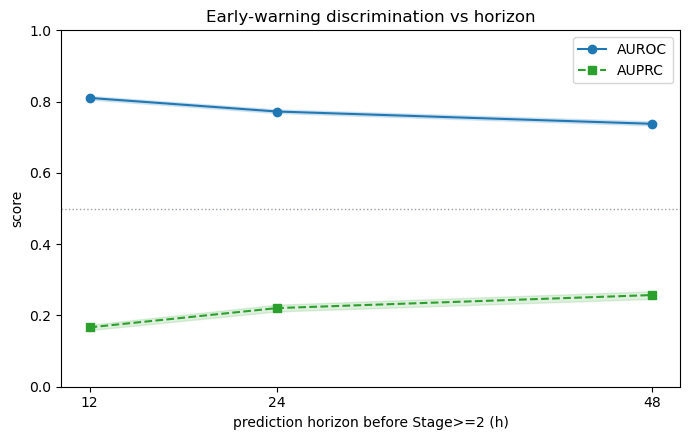

In [23]:
# ============================================================================
# 8f-1 · AUROC & AUPRC vs prediction horizon (early-warning curve)
# ============================================================================
import matplotlib.pyplot as plt
from pathlib import Path
RED, BLUE, GREEN, GREY = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6"
FIG_DIR = PROJECT_ROOT / "figures"; FIG_DIR.mkdir(exist_ok=True)
_H = list(EVAL.horizons_h); _ro=[]; _pr=[]
for H in _H:
    lab = build_escalation_labels(test_scored, horizon_h=H, target_stage=2)
    a,alo,ahi = patient_bootstrap_ci(lab, "risk_score", "y_escalate", "auroc")
    p,plo,phi = patient_bootstrap_ci(lab, "risk_score", "y_escalate", "auprc")
    _ro.append((a,alo,ahi)); _pr.append((p,plo,phi))
_ro=np.array(_ro); _pr=np.array(_pr)
fig,ax=plt.subplots(figsize=(7,4.5))
ax.plot(_H,_ro[:,0],"o-",color=BLUE,label="AUROC")
ax.fill_between(_H,_ro[:,1],_ro[:,2],color=BLUE,alpha=.15)
ax.plot(_H,_pr[:,0],"s--",color=GREEN,label="AUPRC")
ax.fill_between(_H,_pr[:,1],_pr[:,2],color=GREEN,alpha=.15)
ax.axhline(0.5,ls=":",color=GREY,lw=1)
ax.set(xlabel="prediction horizon before Stage>=2 (h)",ylabel="score",
       title="Early-warning discrimination vs horizon",ylim=(0,1))
ax.set_xticks(_H); ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"aki_auc_vs_horizon.png",dpi=150); plt.show()


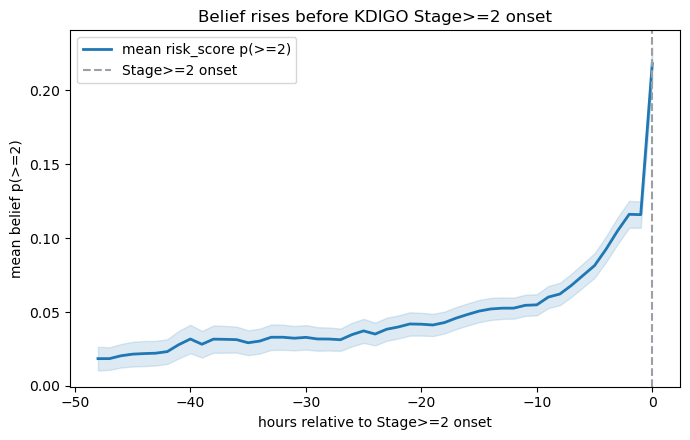

In [24]:
# ============================================================================
# 8f-2 · Mean belief aligned to Stage>=2 onset (lead-time visual)
# ============================================================================
import matplotlib.pyplot as plt
RED, BLUE, GREEN, GREY = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6"
WIN=48
_rows=[]
for sid,g in test_scored.groupby("stay_id",sort=False):
    g=g.sort_values("hour"); sev=(g["kdigo_stage"].to_numpy()>=2)
    if not sev.any(): continue
    onset=g["hour"].to_numpy()[np.argmax(sev)]
    rel=g["hour"].to_numpy()-onset; rs=g["risk_score"].to_numpy()
    m=(rel>=-WIN)&(rel<=0)
    for r,v in zip(rel[m],rs[m]): _rows.append((int(r),v))
_A=pd.DataFrame(_rows,columns=["t","risk"])
_agg=_A.groupby("t")["risk"].agg(["mean","count","std"]).reset_index()
_agg=_agg[_agg["count"]>=30]; _se=_agg["std"]/np.sqrt(_agg["count"])
fig,ax=plt.subplots(figsize=(7,4.5))
ax.plot(_agg["t"],_agg["mean"],"-",color=BLUE,lw=2,label="mean risk_score p(>=2)")
ax.fill_between(_agg["t"],_agg["mean"]-1.96*_se,_agg["mean"]+1.96*_se,color=BLUE,alpha=.15)
ax.axvline(0,ls="--",color=GREY,label="Stage>=2 onset")
ax.set(xlabel="hours relative to Stage>=2 onset",ylabel="mean belief p(>=2)",
       title="Belief rises before KDIGO Stage>=2 onset")
ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"aki_onset_aligned_belief.png",dpi=150); plt.show()


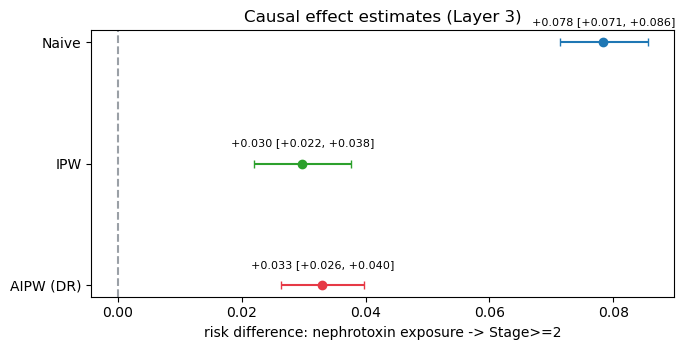

In [25]:
# ============================================================================
# 8f-3 · Causal effect of nephrotoxin -> Stage>=2 (naive / IPW / AIPW)
# ============================================================================
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression as _LR
from sklearn.preprocessing import StandardScaler as _SS
from sklearn.impute import SimpleImputer as _SI
RED, BLUE, GREEN, GREY = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6"
if "ct" not in globals():
    print("Run the Layer-3 causal cell first (defines `ct`).")
else:
    _conf=[c for c in ["age","risk24","stage24","crratio24","bun24","uo24","sepsis","ckd","basecr"] if c in ct.columns]
    d=ct.dropna(subset=["T","Y"]).copy()
    X=_SS().fit_transform(_SI(strategy="median").fit_transform(d[_conf]))
    T=d["T"].to_numpy().astype(int); Y=d["Y"].to_numpy().astype(int)
    ps=_LR(max_iter=1000).fit(X,T).predict_proba(X)[:,1].clip(0.02,0.98)
    m1=_LR(max_iter=1000).fit(X[T==1],Y[T==1]).predict_proba(X)[:,1]
    m0=_LR(max_iter=1000).fit(X[T==0],Y[T==0]).predict_proba(X)[:,1]
    phi_ipw=T*Y/ps-(1-T)*Y/(1-ps)
    phi_aipw=(m1-m0)+T*(Y-m1)/ps-(1-T)*(Y-m0)/(1-ps)
    def _ci(v):
        v=np.asarray(v); s=v.std()/np.sqrt(len(v)); return v.mean(),v.mean()-1.96*s,v.mean()+1.96*s
    rng=np.random.default_rng(7); nb=[]
    for _ in range(2000):
        i=rng.integers(0,len(Y),len(Y))
        if T[i].sum()>5 and (T[i]==0).sum()>5: nb.append(Y[i][T[i]==1].mean()-Y[i][T[i]==0].mean())
    est=[("Naive",np.median(nb),np.percentile(nb,2.5),np.percentile(nb,97.5)),
         ("IPW",*_ci(phi_ipw)),("AIPW (DR)",*_ci(phi_aipw))]
    cols=[BLUE,GREEN,RED]
    fig,ax=plt.subplots(figsize=(7,3.6))
    for k,(nm,e,lo,hi) in enumerate(est):
        ax.errorbar(e,2-k,xerr=[[e-lo],[hi-e]],fmt="o",color=cols[k],capsize=3)
        ax.text(e,2-k+0.14,f"{e:+.3f} [{lo:+.3f}, {hi:+.3f}]",ha="center",fontsize=8)
    ax.axvline(0,ls="--",color=GREY); ax.set_yticks([2,1,0]); ax.set_yticklabels([q[0] for q in est])
    ax.set(xlabel="risk difference: nephrotoxin exposure -> Stage>=2",
           title="Causal effect estimates (Layer 3)")
    plt.tight_layout(); plt.savefig(FIG_DIR/"aki_causal_forest.png",dpi=150); plt.show()


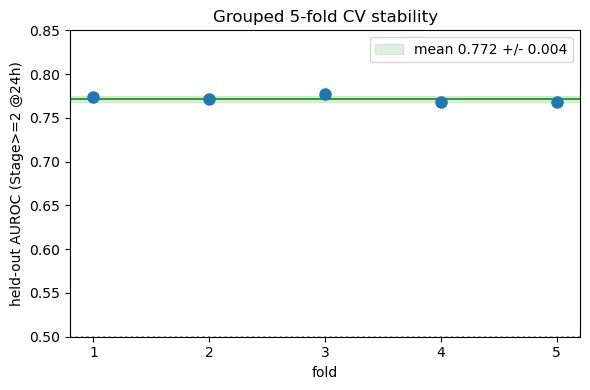

In [26]:
# ============================================================================
# 8f-4 · Grouped 5-fold CV stability
# ============================================================================
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
RED, BLUE, GREEN, GREY = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6"
_l = build_escalation_labels(scored, horizon_h=24, target_stage=2)
_a=[]
for _,te in GroupKFold(n_splits=5).split(_l, groups=_l["subject_id"].to_numpy()):
    h=_l.iloc[te]
    if h["y_escalate"].nunique()==2: _a.append(roc_auc_score(h["y_escalate"],h["risk_score"]))
_a=np.array(_a); mu,sd=_a.mean(),_a.std()
fig,ax=plt.subplots(figsize=(6,4))
ax.axhspan(mu-sd,mu+sd,color=GREEN,alpha=.15,label=f"mean {mu:.3f} +/- {sd:.3f}")
ax.axhline(mu,color=GREEN,lw=1.5)
ax.plot(range(1,len(_a)+1),_a,"o",color=BLUE,ms=8)
ax.axhline(0.5,ls=":",color=GREY)
ax.set(xlabel="fold",ylabel="held-out AUROC (Stage>=2 @24h)",
       title="Grouped 5-fold CV stability",ylim=(0.5,0.85))
ax.set_xticks(range(1,len(_a)+1)); ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"aki_cv_stability.png",dpi=150); plt.show()


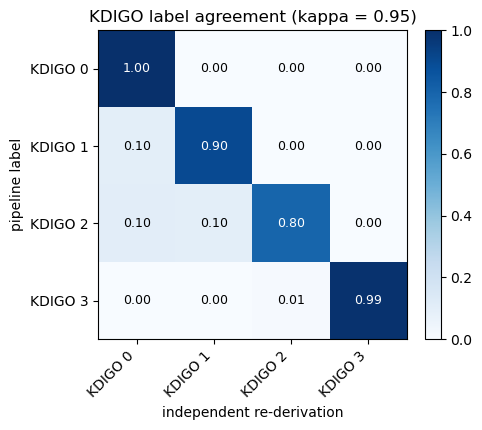

In [27]:
# ============================================================================
# 8f-5 · KDIGO label agreement (pipeline vs independent re-derivation)
# ============================================================================
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
RED, BLUE, GREEN, GREY = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6"
if "_ours" in globals() and "_indep" in globals():
    cm=confusion_matrix(_ours,_indep,labels=[0,1,2,3]).astype(float)
    k=cohen_kappa_score(_ours,_indep)
    cmn=cm/cm.sum(1,keepdims=True).clip(min=1)
    fig,ax=plt.subplots(figsize=(5,4.4))
    im=ax.imshow(cmn,cmap="Blues",vmin=0,vmax=1)
    ax.set_xticks(range(4)); ax.set_yticks(range(4))
    ax.set_xticklabels([f"KDIGO {i}" for i in range(4)],rotation=45,ha="right")
    ax.set_yticklabels([f"KDIGO {i}" for i in range(4)])
    for i in range(4):
        for jj in range(4):
            ax.text(jj,i,f"{cmn[i,jj]:.2f}",ha="center",va="center",
                    color="white" if cmn[i,jj]>.6 else "black",fontsize=9)
    ax.set(xlabel="independent re-derivation",ylabel="pipeline label",
           title=f"KDIGO label agreement (kappa = {k:.2f})")
    fig.colorbar(im,fraction=.046); plt.tight_layout()
    plt.savefig(FIG_DIR/"aki_label_confusion.png",dpi=150); plt.show()
else:
    print("Run the KDIGO label cross-check cell first (defines `_ours`, `_indep`).")


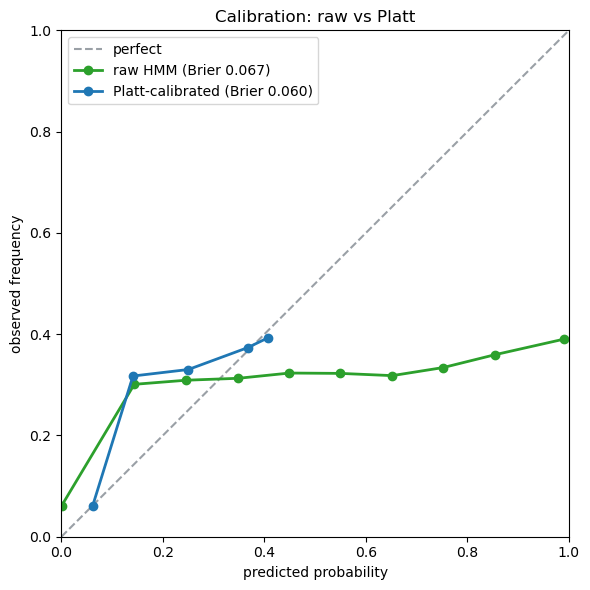

In [28]:
# ============================================================================
# 8f-6 · Calibration: raw HMM vs Platt-calibrated
# ============================================================================
import matplotlib.pyplot as plt
RED, BLUE, GREEN, GREY = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6"
_lab = build_escalation_labels(test_scored, horizon_h=24, target_stage=2)
if "risk_cal" not in _lab.columns and "platt" in globals():
    _lab = _lab.assign(risk_cal=platt.transform(_lab["risk_score"]))
fig,ax=plt.subplots(figsize=(6,6))
ax.plot([0,1],[0,1],"--",color=GREY,label="perfect")
for col,name,c in [("risk_score","raw HMM",GREEN),("risk_cal","Platt-calibrated",BLUE)]:
    if col not in _lab.columns: continue
    rel,br = reliability_table(_lab.assign(p=_lab[col]),"p","y_escalate",bins=10)
    ax.plot(rel["pred"],rel["obs"],"o-",color=c,lw=2,label=f"{name} (Brier {br:.3f})")
ax.set(xlabel="predicted probability",ylabel="observed frequency",
       title="Calibration: raw vs Platt",xlim=(0,1),ylim=(0,1))
ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"aki_calibration_raw_vs_platt.png",dpi=150); plt.show()


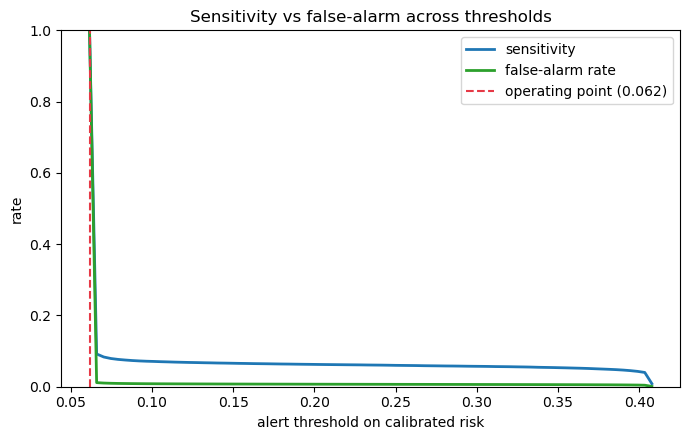

In [29]:
# ============================================================================
# 8f-7 · Sensitivity & false-alarm vs alert threshold (operating characteristics)
# ============================================================================
import matplotlib.pyplot as plt
RED, BLUE, GREEN, GREY = "#e63946", "#1f77b4", "#2ca02c", "#9aa0a6"
_lab = build_escalation_labels(test_scored, horizon_h=24, target_stage=2)
if "risk_cal" not in _lab.columns and "platt" in globals():
    _lab = _lab.assign(risk_cal=platt.transform(_lab["risk_score"]))
_sc = (_lab["risk_cal"] if "risk_cal" in _lab.columns else _lab["risk_score"]).to_numpy()
_y = _lab["y_escalate"].to_numpy()
_hi = float(np.nanquantile(_sc, 0.999))
_ths=np.linspace(_sc.min(), _hi, 80)
_sens=[(_sc[_y==1]>=t).mean() for t in _ths]
_far =[(_sc[_y==0]>=t).mean() for t in _ths]
fig,ax=plt.subplots(figsize=(7,4.5))
ax.plot(_ths,_sens,"-",color=BLUE,lw=2,label="sensitivity")
ax.plot(_ths,_far,"-",color=GREEN,lw=2,label="false-alarm rate")
if "THR_OP" in globals():
    ax.axvline(THR_OP,ls="--",color=RED,label=f"operating point ({THR_OP:.3f})")
ax.set(xlabel="alert threshold on calibrated risk",ylabel="rate",
       title="Sensitivity vs false-alarm across thresholds",ylim=(0,1))
ax.legend(); plt.tight_layout()
plt.savefig(FIG_DIR/"aki_sensitivity_far.png",dpi=150); plt.show()


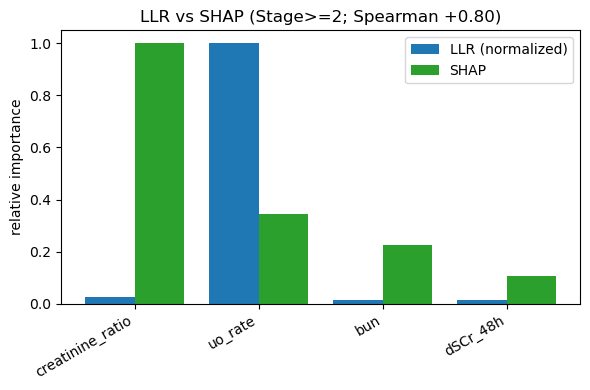

saved figures/aki_llr_vs_shap.png ; Spearman = 0.8


In [3]:
# ============================================================
# Standalone · AKI LLR vs SHAP  (no pipeline cells required)
# ============================================================
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr, norm
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
try:
    import shap as _shap; _HS = True
except Exception:
    _HS = False

BLUE, GREEN = "#1f77b4", "#2ca02c"
FEATURES = ["creatinine_ratio", "dSCr_48h", "uo_rate", "bun"]
CLINICAL_ANCHORS = {                         # copied from the config cell
    "creatinine_ratio": ([1.00, 1.60, 2.40, 3.50], [0.30, 0.35, 0.50, 0.90]),
    "dSCr_48h":         ([0.00, 0.35, 0.60, 1.00], [0.15, 0.20, 0.30, 0.50]),
    "uo_rate":          ([1.00, 0.45, 0.30, 0.10], [0.40, 0.18, 0.13, 0.08]),
    "bun":              ([15.0, 30.0, 45.0, 70.0], [9.0, 12.0, 16.0, 22.0]),
}
FEATURE_WEIGHTS = {"creatinine_ratio": 1.6, "dSCr_48h": 1.3, "uo_rate": 1.5, "bun": 1.0}
TOP = 3  # KDIGO_3

df = pd.read_parquet("derived/aki_cohort_v2.parquet", columns=FEATURES + ["kdigo_stage"])
df = df.dropna(subset=["kdigo_stage"])
if len(df) > 300_000:                        # subsample for speed; importance is stable
    df = df.sample(300_000, random_state=0)
X = df[FEATURES].apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)
for f in FEATURES:                       # clip extreme outliers so nothing overflows float32
    lo, hi = X[f].quantile([0.001, 0.999])
    X[f] = X[f].clip(lo, hi)
X = X.fillna(X.median())
y = (df["kdigo_stage"].to_numpy() >= 2).astype(int)

llr = {}
for f in FEATURES:
    mu, sd = CLINICAL_ANCHORS[f]; w = FEATURE_WEIGHTS[f]; x = X[f].to_numpy()
    llr[f] = float(np.mean(np.abs(w * (norm.logpdf(x, mu[TOP], sd[TOP]) -
                                       norm.logpdf(x, mu[0],   sd[0])))))
llr = pd.Series(llr)

gbm = GradientBoostingClassifier(max_depth=3, n_estimators=150, random_state=0).fit(X, y)
if _HS:
    r = _shap.TreeExplainer(gbm).shap_values(X)
    if isinstance(r, list): r = r[-1]
    r = np.asarray(r); r = r[:, :, -1] if r.ndim == 3 else r
    shap_imp = pd.Series(np.abs(r).mean(0), index=FEATURES)
else:
    lin = LogisticRegression(max_iter=2000).fit(X, y)
    shap_imp = pd.Series(np.abs(lin.coef_[0]) * X.std().values, index=FEATURES)

c = pd.DataFrame({"LLR": llr, "SHAP": shap_imp}).sort_values("SHAP", ascending=False)
rho = spearmanr(c["LLR"].rank(ascending=False), c["SHAP"].rank(ascending=False)).correlation
nz = lambda s: s / (s.max() if s.max() > 0 else 1.0)
xv = np.arange(len(c)); wd = 0.4
Path("figures").mkdir(exist_ok=True)
plt.figure(figsize=(6, 4))
plt.bar(xv - wd/2, nz(c["LLR"]),  wd, label="LLR (normalized)", color=BLUE)
plt.bar(xv + wd/2, nz(c["SHAP"]), wd, label="SHAP", color=GREEN)
plt.xticks(xv, c.index, rotation=30, ha="right"); plt.ylabel("relative importance")
plt.title(f"LLR vs SHAP (Stage>=2; Spearman {rho:+.2f})"); plt.legend()
plt.tight_layout(); plt.savefig("figures/aki_llr_vs_shap.png", dpi=150); plt.show()
print("saved figures/aki_llr_vs_shap.png ; Spearman =", round(rho, 3))